In [1]:
import math

In [2]:
from math import*

In [3]:
import numpy as np

In [4]:
import pandas as pd

In [5]:
#import polars as pl

In [6]:
import pyarrow.parquet as pq

In [7]:
import matplotlib.pyplot as plt

In [8]:
def delta_p_df(df):
    return df.diff(axis=1).iloc[:, 1:]

In [9]:
def convert_to_matrix(subset_data):
    return subset_data.to_numpy()

In [10]:
def covariance_to_correlation(cov_matrix):
    variances = np.diag(cov_matrix)
    std_deviations = np.sqrt(variances)
    std_outer = np.outer(std_deviations, std_deviations)
    correlation_matrix = cov_matrix/std_outer
    return correlation_matrix

In [11]:
def split_column_name(col_name):
    parts = [int(x) for x in col_name.split("_")]
    return (parts[2],parts[1],parts[0])

def subset_site_cols_organized(dataframe, location):
    '''takes in dataframe as a table and a location number as a string and returns the subset'''
    cols_selected = [
        col for col in dataframe.columns
        if col == "1_0_1" or col.split("_")[0] == location
    ]
    subset_site = dataframe[cols_selected]

    sorted_columns = sorted(subset_site.columns, key=split_column_name)
    subset_site_organized = subset_site[sorted_columns]
    
    return subset_site_organized

In [12]:
seedmix = pd.read_csv("seedmix_hapfire_allele_frequency_random_switch_fixrm.csv", nrows=5000)

In [13]:
master_df = pd.read_csv("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.csv", nrows=5000)

In [14]:
master_df.insert(loc=0, column="1_0_1", value = seedmix["X3"])

In [15]:
full_seedmix = pd.read_csv("seedmix_hapfire_allele_frequency_random_switch_fixrm.csv", usecols=['X3'])

In [16]:
#lazy_df = pl.scan_csv("PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.csv", null_values='NA').sink_parquet('output.parquet', compression='zstd')

In [17]:
def lazy_load(file_path, df_master, location, replicate):
    '''lazy load the columns needed'''

    if replicate == 'None':
        cols_selected = [
            col for col in df_master.columns
            if col != '1_0_1' and col.split("_")[0] == location
        ]

    else:
    
        cols_selected = [
            col for col in df_master.columns
            if col != '1_0_1' and col.split("_")[0] == location and col.split("_")[-1] == replicate
        ]

    cols_sorted = sorted(cols_selected, key=split_column_name)

    df = pd.read_parquet(file_path, columns=cols_sorted)
    
    df.insert(0, '1_0_1', full_seedmix['X3'])
    
    return df

In [18]:
# file_path = "mutation_frequencies_sim12rep.csv"

# with open(file_path, 'r') as f:
#     max_cols = max(len(line.split(',')) for line in f)

# col_names = [f"col_{i}" for i in range(max_cols)]

# df = pd.read_csv(
#     file_path, 
#     names=col_names, 
#     header=None,  
#     engine='python'
# )
# dft = df.T

# dft.columns = dft.iloc[0]

# dft = dft.iloc[1:].reset_index(drop=True)

# dft.to_csv("transposed_mut_freq_sim12rep_11-2.csv", index=False, header=True)

In [20]:
import polars as pl

# lazy_sims = pl.scan_csv("transposed_mut_freq_sim12rep_11-2.csv", null_values='NA').sink_parquet("sim12reps.parquet", compression="zstd")
sim_path = pd.read_csv("transposed_mut_freq_sim12rep_11-2.csv", nrows=0)

def lazy_load_sims(file_path, sim_path, sim_num):
    '''lazy load the columns needed'''

    cols_selected = [col for col in sim_path.filter(regex=f'_{sim_num}s|Xs{sim_num}_|Ys{sim_num}_').columns]

    df = pd.read_parquet(file_path, columns=cols_selected)
    
    return df

In [22]:
lazy_load_sims("sim12reps.parquet", sim_path, 1)

,pos_15000_1s,p0_15000_1s,pos_15001_1s,Xs1_15001_p1,Xs1_15001_p2,Xs1_15001_p3,Xs1_15001_p4,Xs1_15001_p5,Xs1_15001_p6,Ys1_15001_p7,...,Xs1_15003_p3,Xs1_15003_p4,Xs1_15003_p5,Xs1_15003_p6,Ys1_15003_p7,Ys1_15003_p8,Ys1_15003_p9,Ys1_15003_p10,Ys1_15003_p11,Ys1_15003_p12
0,969273.0,0.197333,969273.0,0.176000,0.176333,0.175000,0.195667,0.182333,0.192333,0.175333,...,0.167000,0.175000,0.177333,0.205667,0.174000,0.163000,0.184000,0.160667,0.188000,0.146667
1,44028.0,0.457000,44028.0,0.487333,0.484000,0.452333,0.469333,0.472000,0.467667,0.425333,...,0.458000,0.489333,0.455000,0.478667,0.414000,0.502667,0.497333,0.453333,0.464667,0.455333
2,67427.0,0.155000,67427.0,0.153333,0.173000,0.158333,0.170667,0.165667,0.156333,0.158333,...,0.156333,0.164000,0.168000,0.137667,0.161000,0.167333,0.168000,0.179667,0.144333,0.167667
3,346192.0,0.006000,346192.0,0.021667,0.008333,0.013333,0.011333,0.015667,0.010333,0.008667,...,0.012667,0.009000,0.013333,0.008667,0.008667,0.004000,0.006667,0.005667,0.010333,0.005333
4,465810.0,0.003667,465810.0,0.000000,0.007333,0.001333,0.005667,0.006000,0.000000,0.002333,...,0.001333,0.004000,0.003000,0.000000,0.004667,0.000333,0.000000,0.003000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
898,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
899,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
901,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#lazy_load("PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, '57', 'None').cov()

In [23]:
def array_the_reps(master_matrix_df):
    return sorted(list(set(int(col.split('_')[2]) for col in master_matrix_df.columns)))

In [24]:
def array_the_gens(master_matrix_df):
    return sorted(list(set(int(col.split('_')[1]) for col in master_matrix_df.columns)))

In [25]:
sites = sorted(list(set(int(col.split('_')[0]) for col in master_df.columns)))

In [26]:
def delta_p_all_reps_at_site(site):
    rep_list = array_the_reps(subset_site_cols_organized(master_df, site))
    delta_p_list = []
    for r in rep_list:
        rep_df = subset_site_cols_organized(lazy_load("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, site, str(r)), site)
        delta_p = delta_p_df(rep_df)
        delta_p_list.append(delta_p)

    combined_delta_p = pd.concat(delta_p_list, axis=1)

    return combined_delta_p

In [27]:
# # Creates new dataframe built by the delta_p per replicate at a site, computes the covariance

# def delta_p_all_reps_at_site(site, lazy_flag = False):
#     rep_list = array_the_reps(subset_site_cols_organized(master_df, site))

#     if lazy_flag:
#         delta_p_list = []
#         for r in rep_list:
#             rep_df = subset_site_cols_organized(lazy_load("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, site, str(r)), site)
#             delta_p = delta_p_df(rep_df)
#             delta_p_list.append(delta_p)

#         combined_delta_p = pd.concat(delta_p_list, axis=1, join='inner')
#     else:
#         delta_p_list = []
#         for r in rep_list:
#             rep_df = subset_site_cols_organized(master_df, site) #fix to loop through r
#     return combined_delta_p

In [28]:
from itertools import combinations

def convergent_correlation(cov_for_all_reps, generations, replicates):
    labels = [f'Gen_{g}' for g in generations]
    conv_corr_matrix = pd.DataFrame(np.nan, index = labels, columns = labels)

    columns_map = {}
    for col in cov_for_all_reps.columns:
        parts = col.split("_")
        if len(parts)>=3:
            columns_map[(str(parts[1]), str(parts[2]))] = col
    
    reps_str = [str(r) for r in replicates]

    for i, g1 in enumerate(generations):
        for g2 in generations[i:]:
            s, t = str(g1), str(g2)
            pair_correlations = []

            if s==t:
                rep_pairs = [(r,r) for r in reps_str]

            else:
                rep_pairs = list(combinations(reps_str, 2))

            for rep_A, rep_B in rep_pairs:
                col_s_A = columns_map.get((s, rep_A))
                col_t_B = columns_map.get((t, rep_B))
                col_s_B = columns_map.get((s, rep_B))
                col_t_A = columns_map.get((t, rep_A))

                if not (col_s_A and col_t_B and col_s_B and col_t_A):
                    continue

                cov_1 = np.nanmean(cov_for_all_reps.loc[col_s_A, col_t_B])
                var_s_A = cov_for_all_reps.loc[col_s_A, col_s_A]
                var_t_B = cov_for_all_reps.loc[col_t_B, col_t_B]

                cov_2 = np.nanmean(cov_for_all_reps.loc[col_t_A, col_s_B])
                var_t_A = cov_for_all_reps.loc[col_t_A, col_t_A]
                var_s_B = cov_for_all_reps.loc[col_s_B, col_s_B]

                denom1 = np.nanmean(np.sqrt(var_s_A*var_t_B))
                denom2 = np.nanmean(np.sqrt(var_t_A*var_s_B))

                if denom1>0 and denom2>0:
                    corr1 = cov_1/denom1
                    corr2 = cov_2/denom2
                    pair_correlations.append((corr1+corr2)/2.0)

            val = pair_correlations if pair_correlations else np.nan
            conv_corr_matrix.loc[f"Gen_{s}", f"Gen_{t}"] = val
            conv_corr_matrix.loc[f"Gen_{t}", f"Gen_{s}"] = val

    return conv_corr_matrix

In [29]:
from itertools import product

def between_sites(site1, site2, gens1, gens2, reps1, reps2, site1_id, site2_id):

    gens = sorted(list(set(gens1) & set(gens2)))
    
    reps_1 = [str(r) for r in reps1]
    reps_2 = [str(r) for r in reps2]

    correlations_through_time = {}
    for g in gens:
        str_g = str(g)
        cols_site1 = [col for col in site1.columns if col.split("_")[1] == str_g]
        cols_site2 = [col for col in site2.columns if col.split("_")[1] == str_g]

        site1_time_g = site1[cols_site1]
        site2_time_g = site2[cols_site2]

        cov_sites_time_g = pd.concat([site1_time_g, site2_time_g], axis = 1).dropna().cov()

        columns_map = {}
        for col in cov_sites_time_g.columns:
            parts = col.split("_")
            if len(parts)>=3:
                columns_map[(str(parts[0]), str(parts[2]))] = col
        
        rep_pairs = list(product(reps_1, reps_2))

        s1, s2 = str(site1_id), str(site2_id)
        
        correlations = []
        for rep1, rep2 in rep_pairs:
            cols_s1_rep1 = columns_map.get((s1, rep1))
            cols_s2_rep2 = columns_map.get((s2, rep2))

            if not (cols_s1_rep1 and cols_s2_rep2):
                continue 

            cov = np.nanmean(cov_sites_time_g.loc[cols_s1_rep1, cols_s2_rep2])
            var_s1_rep1 = cov_sites_time_g.loc[cols_s1_rep1, cols_s1_rep1]
            var_s2_rep2 = cov_sites_time_g.loc[cols_s2_rep2, cols_s2_rep2]

            denom = np.nanmean(np.sqrt(var_s1_rep1*var_s2_rep2))
            if denom>0:
                corr = cov/denom

                correlations.append(corr)

        val = corr if corr else np.nan
        
        correlations_through_time[g] = val

    return pd.Series(correlations_through_time)

In [30]:
# lazy load the sims

In [ ]:
file_path = "mutation_frequencies_sim12rep.csv"

with open(file_path, 'r') as f:
    max_cols = max(len(line.split(',')) for line in f)

col_names = [f"col_{i}" for i in range(max_cols)]

df = pd.read_csv(
    file_path, 
    names=col_names, 
    header=None,  
    engine='python'
)
dft = df.T

dft.columns = dft.iloc[0]

dft = dft.iloc[1:].reset_index(drop=True)


In [ ]:
def delta_p_all_reps_sim(df):
    rep_list = list(dict.fromkeys(sorted((col.split('_')[2]) for col in df.columns)))[1:]
    delta_p_list = []
    for r in rep_list:
        rep_df = df.filter(regex=f"{r}|p0")
        delta_p = delta_p_df(rep_df)
        delta_p_list.append(delta_p)

    combined_delta_p = pd.concat(delta_p_list, axis=1)

    return combined_delta_p

In [35]:

test2 = list(dict.fromkeys(sorted((col.split('_')[2]) for col in delta_p_Y.columns)))
print(test2)
test = sorted((col.split('_')[2]) for col in delta_p_Y.columns)
print(test)
rep_list = list(dict.fromkeys(sorted((col.split('_')[2]) for col in matches.columns)))[1:]
print(rep_list)

delta_p_all_reps_sim(site_Y)


['p10', 'p11', 'p12', 'p7', 'p8', 'p9']
['p10', 'p10', 'p10', 'p11', 'p11', 'p11', 'p12', 'p12', 'p12', 'p7', 'p7', 'p7', 'p8', 'p8', 'p8', 'p9', 'p9', 'p9']
['p1', 'p10', 'p11', 'p12', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'p8', 'p9']


col_0,Ys2_15001_p10,Ys2_15002_p10,Ys2_15003_p10,Ys2_15001_p11,Ys2_15002_p11,Ys2_15003_p11,Ys2_15001_p12,Ys2_15002_p12,Ys2_15003_p12,Ys2_15001_p7,Ys2_15002_p7,Ys2_15003_p7,Ys2_15001_p8,Ys2_15002_p8,Ys2_15003_p8,Ys2_15001_p9,Ys2_15002_p9,Ys2_15003_p9
0,0.001000,-0.003666,0.003000,0.003000,-0.006000,-0.007666,-0.001000,-0.015000,-0.001333,-0.007000,0.001000,-0.013666,-0.019333,0.010000,-0.002667,0.005667,-0.004333,-0.004000
1,0.004667,0.006333,0.006000,-0.010667,0.003333,-0.001333,-0.001000,-0.007000,-0.002333,0.004000,-0.002667,0.001000,-0.007667,-0.005667,-0.003333,-0.006000,-0.002333,-0.003000
2,0.000333,0.001000,0.000000,NaN,NaN,NaN,0.001667,-0.000333,-0.000667,0.001667,0.000000,0.001000,0.001000,0.000000,-0.000667,0.001333,-0.000667,0.000667
3,0.004000,-0.001667,-0.000333,-0.001667,0.000333,-0.001000,0.000000,-0.000667,0.001000,0.004000,0.000667,-0.001000,0.000000,0.000000,0.001667,-0.000667,0.001333,-0.000333
4,0.011667,0.004667,0.003333,-0.007000,-0.000667,-0.004000,-0.004667,-0.001667,-0.005333,-0.001000,-0.002333,0.001000,0.008333,-0.001667,0.004000,-0.002667,-0.008333,-0.001000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000333,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
514,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
515,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.001000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000667,-0.000667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
sim_num = "2"

sub_df = dft.filter(regex=f'_{sim_num}s|Xs{sim_num}_|Ys{sim_num}_')
    
sub_15000 = sub_df.filter(like="15000").copy().reset_index(drop=True)
sub_15001 = sub_df.filter(like="15001").copy().reset_index(drop=True)
sub_15002 = sub_df.filter(like="15002").copy().reset_index(drop=True)
sub_15003 = sub_df.filter(like="15003").copy().reset_index(drop=True)

matches_1 = pd.merge(sub_15000, sub_15001, how='left', left_on= sub_15000.columns[0], right_on=sub_15001.columns[0]).dropna()
matches_2 = pd.merge(matches_1, sub_15002, how='left', left_on= matches_1.columns[0], right_on=sub_15002.columns[0]).dropna()
matches = pd.merge(matches_2, sub_15003, how='left', left_on= matches_2.columns[0], right_on=sub_15003.columns[0]).dropna()
matches = matches.loc[:, ~matches.columns.str.contains("pos")].copy().reset_index(drop=True)
matches = matches.replace(0, np.nan).replace(1, np.nan)

site_X = matches.filter(regex="p0|Xs")
site_Y = matches.filter(regex="p0|Ys")

delta_p_X = delta_p_all_reps_sim(site_X)
delta_p_Y = delta_p_all_reps_sim(site_Y)

gens = [15001, 15002, 15003]
reps_X = list(dict.fromkeys(sorted((col.split('_')[2]) for col in delta_p_X.columns)))
reps_Y = list(dict.fromkeys(sorted((col.split('_')[2]) for col in delta_p_Y.columns)))

between_sites(delta_p_X, delta_p_Y, gens, gens, reps_X, reps_Y, f'Xs{sim_num}', f'Ys{sim_num}')
#between_sites(delta_p_X, delta_p_Y, gens, gens, reps_X, reps_Y, 'Xs1', 'Ys1')

15001    0.527939
15002   -0.074640
15003    0.399822
dtype: float64

In [45]:
site_X

col_0,p0_15000_1s,Xs1_15001_p1,Xs1_15001_p2,Xs1_15001_p3,Xs1_15001_p4,Xs1_15001_p5,Xs1_15001_p6,Xs1_15002_p1,Xs1_15002_p2,Xs1_15002_p3,Xs1_15002_p4,Xs1_15002_p5,Xs1_15002_p6,Xs1_15003_p1,Xs1_15003_p2,Xs1_15003_p3,Xs1_15003_p4,Xs1_15003_p5,Xs1_15003_p6
0,0.095000,0.098333,0.102667,0.112667,0.104000,0.095000,0.100000,0.107333,0.103000,0.118,0.108667,0.104667,0.104333,0.108000,0.099000,0.119000,0.106333,0.106667,0.105333
1,0.001000,NaN,0.000667,NaN,0.000333,0.004000,0.001000,NaN,0.000667,NaN,NaN,0.003333,0.001667,NaN,0.000333,NaN,NaN,0.004000,0.002000
2,0.001333,0.000667,NaN,NaN,0.000333,0.001000,NaN,0.001667,NaN,NaN,0.000333,0.000333,NaN,0.002000,NaN,NaN,NaN,0.000333,NaN
3,0.005333,0.008000,0.006000,0.006000,0.004000,0.003000,0.003333,0.006333,0.004333,0.007,0.004000,0.003000,0.004000,0.007000,0.005000,0.003333,0.006000,0.003333,0.004333
4,0.673333,0.673333,0.686667,0.681667,0.685333,0.673667,0.669333,0.679333,0.679333,0.670,0.678333,0.689000,0.652333,0.670333,0.672000,0.683000,0.678667,0.686667,0.669667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
528,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
530,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
import pathlib

simulated_convergences = pathlib.Path("simulated_conv_corr_10-23-2.csv")

for sim_num in range(1,101):
    sub_df = dft.filter(regex=f'_{sim_num}s|Xs{sim_num}_|Ys{sim_num}_')
    
    sub_15000 = sub_df.filter(like="15000").copy().reset_index(drop=True)
    sub_15001 = sub_df.filter(like="15001").copy().reset_index(drop=True)
    sub_15002 = sub_df.filter(like="15002").copy().reset_index(drop=True)
    sub_15003 = sub_df.filter(like="15003").copy().reset_index(drop=True)

    matches_1 = pd.merge(sub_15000, sub_15001, how='left', left_on= sub_15000.columns[0], right_on=sub_15001.columns[0]).dropna()
    matches_2 = pd.merge(matches_1, sub_15002, how='left', left_on= matches_1.columns[0], right_on=sub_15002.columns[0]).dropna()
    matches = pd.merge(matches_2, sub_15003, how='left', left_on= matches_2.columns[0], right_on=sub_15003.columns[0]).dropna()
    matches = matches.loc[:, ~matches.columns.str.contains("pos")].copy().reset_index(drop=True)
    matches = matches.replace(0, np.nan)

    site_X = matches.filter(regex="p0|Xs")
    site_Y = matches.filter(regex="p0|Ys")

    delta_p_X = delta_p_all_reps_sim(site_X)
    delta_p_Y = delta_p_all_reps_sim(site_Y)

    gens = [15001, 15002, 15003]
    reps_X = list(dict.fromkeys(sorted((col.split('_')[2]) for col in delta_p_X.columns)))
    reps_Y = list(dict.fromkeys(sorted((col.split('_')[2]) for col in delta_p_Y.columns)))

    res_series = between_sites(delta_p_X, delta_p_Y, gens, gens, reps_X, reps_Y, f'Xs{sim_num}', f'Ys{sim_num}')

    for year, corr_val in res_series.items():
             rows = {"sim_num": str(sim_num), "year": year, "convergence_correlation": corr_val}
             print(f"Finished sim {sim_num}, year {year}")
             simulated_convergences_df = pd.DataFrame(rows, index = [0])
             simulated_convergences_df.to_csv("simulated_conv_corr_10-23-2.csv", index=False, mode='a', header=not simulated_convergences.exists())

Finished sim 1, year 15001
Finished sim 1, year 15002
Finished sim 1, year 15003
Finished sim 2, year 15001
Finished sim 2, year 15002
Finished sim 2, year 15003
Finished sim 3, year 15001
Finished sim 3, year 15002
Finished sim 3, year 15003
Finished sim 4, year 15001
Finished sim 4, year 15002
Finished sim 4, year 15003
Finished sim 5, year 15001
Finished sim 5, year 15002
Finished sim 5, year 15003
Finished sim 6, year 15001
Finished sim 6, year 15002
Finished sim 6, year 15003
Finished sim 7, year 15001
Finished sim 7, year 15002
Finished sim 7, year 15003
Finished sim 8, year 15001
Finished sim 8, year 15002
Finished sim 8, year 15003
Finished sim 9, year 15001
Finished sim 9, year 15002
Finished sim 9, year 15003
Finished sim 10, year 15001
Finished sim 10, year 15002
Finished sim 10, year 15003
Finished sim 11, year 15001
Finished sim 11, year 15002
Finished sim 11, year 15003
Finished sim 12, year 15001
Finished sim 12, year 15002
Finished sim 12, year 15003
Finished sim 13, ye

In [29]:
sub_df.filter(like="15000").dropna().reset_index(drop=True).tail(50)

col_0,pos_15000_1s,p0_15000_1s
655,919890.0,0.0
656,397500.0,0.0
657,663399.0,0.0
658,503699.0,0.0
659,632169.0,0.0
660,392869.0,0.0
661,648967.0,0.0
662,57462.0,0.0
663,560696.0,0.0
664,496830.0,0.0


In [30]:
# if p=0 for p0, convert 0 to NA
# if p=0 for p>0, convert 0 to NA
# convert 1 to NA

delta_p_X = delta_p_all_reps_sim(site_X)
delta_p_Y = delta_p_all_reps_sim(site_Y)
delta_p_all_reps_sim(site_X).head(50)

NameError: name 'site_X' is not defined

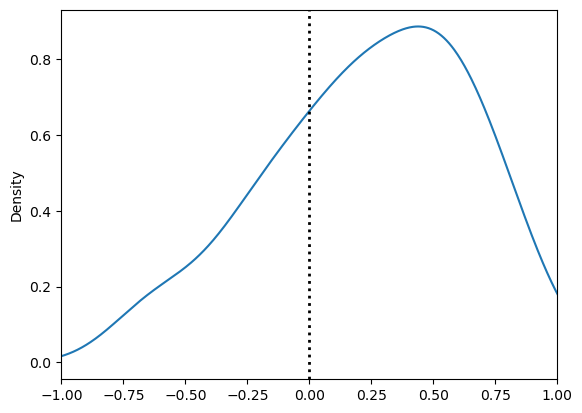

In [29]:
sim_convergences = pd.read_csv("simulated_conv_corr_10-23-2.csv")
# sum(sim_convergences['convergence_correlation'] > 1)
sim_convergences[sim_convergences['year']==15001]['convergence_correlation'].plot.kde()
plt.axvline(x=0, color='black', linestyle=':', linewidth=2)

plt.xlim(-1, 1)
plt.show()

In [ ]:
# Good for using on mutation_frequencies_sims2.csv

for i in range(1,1001):
    sub_df = dft.iloc[:, (i*11-11):(i*11)]
    
    sub_15000 = sub_df.filter(like="15000").dropna().copy().reset_index(drop=True)
    sub_15001 = sub_df.filter(like="15001").dropna().copy().reset_index(drop=True)
    sub_15002 = sub_df.filter(like="15002").dropna().copy().reset_index(drop=True)
    sub_15003 = sub_df.filter(like="15003").dropna().copy().reset_index(drop=True)

    matches_1 = pd.merge(sub_15000, sub_15001, how='left', left_on= sub_15000.columns[0], right_on=sub_15001.columns[0]).dropna()
    matches_2 = pd.merge(matches_1, sub_15002, how='left', left_on= matches_1.columns[0], right_on=sub_15002.columns[0]).dropna()
    matches = pd.merge(matches_2, sub_15003, how='left', left_on= matches_2.columns[0], right_on=sub_15003.columns[0]).dropna()
    matches = matches.loc[:, ~matches.columns.str.contains("pos")].copy().reset_index(drop=True)

    delta_pop2 = delta_p_df(matches.filter(regex="p0|p2"))
    delta_pop3 = delta_p_df(matches.filter(regex="p0|p3"))
    #concat = pd.concat([delta_pop2, delta_pop3], axis=1)

    gens = [15001, 15002, 15003]
    reps = sorted((col.split('_')[2]) for col in matches.columns)

    between_sites(delta_pop2, delta_pop3, gens, gens, reps, reps, 'p2', 'p3')

In [27]:
df_1 = dft.iloc[:,:11]
df_1
df_2 = dft.iloc[:,11:22]
df_2

col_0,pos_15000_s2,p0_15000_s2,pos_15001_s2,p2_15001_s2,p3_15001_s2,pos_15002_s2,p2_15002_s2,p3_15002_s2,pos_15003_s2,p2_15003_s2,p3_15003_s2
0,311096.0,0.192333,311096.0,0.19,0.195667,311096.0,0.193667,0.19,311096.0,0.182667,0.189667
1,249096.0,0.017667,249096.0,0.023,0.015,249096.0,0.022,0.012667,249096.0,0.019667,0.016
2,243754.0,0.998333,243754.0,0.998333,0.999,243754.0,0.997,0.998667,243754.0,0.996333,0.999667
3,507516.0,0.000333,507516.0,0.0,0.002333,507516.0,0.0,0.002667,507516.0,0.0,0.003
4,784885.0,0.0,784885.0,0.000333,0.0,784885.0,0.000667,0.0,784885.0,0.001,0.0
...,...,...,...,...,...,...,...,...,...,...,...
593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
594,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
596,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [59]:
i = 1
sub_df = dft.iloc[:, (i*11-11):(i*11)]
sub_df
sub_15000 = sub_df.filter(like="15000").dropna().copy().reset_index(drop=True)
sub_15001 = sub_df.filter(like="15001").dropna().copy().reset_index(drop=True)
sub_15002 = sub_df.filter(like="15002").dropna().copy().reset_index(drop=True)
sub_15003 = sub_df.filter(like="15003").dropna().copy().reset_index(drop=True)

matches_1 = pd.merge(sub_15000, sub_15001, how='left', left_on= sub_15000.columns[0], right_on=sub_15001.columns[0])
matches_2 = pd.merge(matches_1, sub_15002, how='left', left_on= matches_1.columns[0], right_on=sub_15002.columns[0])
matches = pd.merge(matches_2, sub_15003, how='left', left_on= matches_2.columns[0], right_on=sub_15003.columns[0]).dropna()
matches = matches.loc[:, ~matches.columns.str.contains("pos")].copy().reset_index(drop=True)
# matches.columns.get_loc("p0_15000_s1")
delta_pop2 = delta_p_df(matches.filter(regex="p0|p2"))
delta_pop2
reps = sorted((col.split('_')[2]) for col in matches.columns)
reps

['s1', 's1', 's1', 's1', 's1', 's1', 's1']

In [28]:
df_1.filter(regex="15000").dropna().copy().reset_index(drop=True)

col_0,pos_15000_s1,p0_15000_s1
0,897297.0,0.385
1,742596.0,0.004333
2,372303.0,0.01
3,832507.0,0.038667
4,446673.0,0.001
...,...,...
377,419093.0,0.0
378,187425.0,0.0
379,776021.0,0.0
380,696795.0,0.0


In [33]:
df_1.filter(regex="15000").dropna().copy().reset_index(drop=True).columns.get_loc("pos_15000_s1")

0

In [66]:
#df_1 filter (simulation 1 = s1)
s1_15000 = df_1.filter(regex="15000").dropna(subset=['pos_15000_s1']).copy()
s1_15001 = df_1.filter(like="15001").dropna(subset=['pos_15001_s1']).copy()
s1_15002 = df_1.filter(like="15002").dropna(subset=['pos_15002_s1']).copy()
s1_15003 = df_1.filter(like="15003").dropna(subset=['pos_15003_s1']).copy()

first_merge = pd.merge(cols_15000, cols_15001, how='left', left_on='pos_15000_s1', right_on='pos_15001_s1')
second_merge = pd.merge(first_merge, cols_15002, how='left', left_on='pos_15000_s1', right_on='pos_15002_s1')
third_merge = pd.merge(second_merge, cols_15003, how='left', left_on='pos_15000_s1', right_on='pos_15003_s1')
third_merge = third_merge.dropna().drop(columns = ['pos_15000_s1','pos_15001_s1', 'pos_15002_s1', 'pos_15003_s1'])
# positions = third_merge.filter(like='pos').dropna()
# sum(positions["pos_initial_1"]==positions['pos_15003_s1'])
delta_p2_s1 = delta_p_df(third_merge.filter(regex="^(p0_15000_s1)$|p2"))
delta_p3_s1 = delta_p_df(third_merge.filter(regex="^(p0_15000_s1)$|p3"))
# concatted = pd.concat([delta_p2_s1, delta_p3_s1], axis=1)
# concatted.dropna()

#df_2 filter (simulation 1 = s2)
s2_15000 = df_2.filter(regex="15000").dropna(subset=['pos_15000_s2']).copy()
s2_15001 = df_2.filter(like="15001").dropna(subset=['pos_15001_s2']).copy()
s2_15002 = df_2.filter(like="15002").dropna(subset=['pos_15002_s2']).copy()
s2_15003 = df_2.filter(like="15003").dropna(subset=['pos_15003_s2']).copy()

merge_1 = pd.merge(s2_15000, s2_15001, how='left', left_on='pos_15000_s2', right_on='pos_15001_s2')
merge_2 = pd.merge(merge_1, s2_15002, how='left', left_on='pos_15000_s2', right_on='pos_15002_s2')
merge_3 = pd.merge(merge_2, s2_15003, how='left', left_on='pos_15000_s2', right_on='pos_15003_s2')
merge_3 = merge_3.dropna().drop(columns = ['pos_15000_s2','pos_15001_s2', 'pos_15002_s2', 'pos_15003_s2'])
# positions = third_merge.filter(like='pos').dropna()
# sum(positions["pos_initial_1"]==positions['pos_15003_s1'])
delta_p2_s2 = delta_p_df(merge_3.filter(regex="^(p0_15000_s2)$|p2"))
delta_p3_s2 = delta_p_df(merge_3.filter(regex="^(p0_15000_s2)$|p3"))

concat_p2 = pd.concat([delta_p2_s1, delta_p2_s2], axis = 1)
concat_p3 = pd.concat([delta_p3_s1, delta_p3_s2], axis = 1)

In [67]:
concat_p2 = pd.concat([delta_p2_s1, delta_p2_s2], axis = 1)
concat_p3 = pd.concat([delta_p3_s1, delta_p3_s2], axis = 1)
gens = [15001, 15002, 15003]
reps_2 = ['s1', 's1', 's1', 's2', 's2', 's2']
reps_3 = ['s1', 's1', 's1', 's2', 's2', 's2']

between_sites(concat_p2, concat_p3, gens, gens, reps_2, reps_3, 'p2', 'p3')

15001    0.052072
15002   -0.230213
15003    0.157287
dtype: float64

In [60]:
delta_p2 = delta_p_df(third_merge.filter(regex="^(p0_15000_s1)$|p2"))
delta_p3 = delta_p_df(third_merge.filter(regex="^(p0_15000_s1)$|p3"))
gens = [15001, 15002, 15003]
reps_2 = ['s1', 's1', 's1', 's2', 's2', 's2']
reps_3 = ['s1', 's1', 's1']

between_sites(delta_p2, delta_p3, gens, gens, reps_2, reps_3, 'p2', 'p3')

15001    0.50689
15002   -0.03312
15003    0.47396
dtype: float64

In [37]:
delta_p2 = delta_p_df(third_merge.filter(regex="^(p0_15000_p0)$|p2"))
delta_p3 = delta_p_df(third_merge.filter(regex="^(p0_15000_p0)$|p3"))
gens = [15001, 15002, 15003]
reps_2 = ['p2', 'p2', 'p2']
reps_3 = ['p3', 'p3', 'p3']

between_sites(delta_p2, delta_p3, gens, gens, reps_2, reps_3, 'p2', 'p3')

15001    0.646507
15002   -0.542235
15003   -0.191847
dtype: float64

In [30]:
dft.filter(like="15001")

col_0,pos_15001,p2_15001_p2,p3_15001_p3
0,891273.0,0.000333,0.000333
1,379686.0,0.001667,0.001
2,851576.0,0.017333,0.016
3,111213.0,0.0,0.000333
4,8700.0,0.002667,0.001
...,...,...,...
430,NaN,NaN,NaN
431,NaN,NaN,NaN
432,NaN,NaN,NaN
433,NaN,NaN,NaN


In [26]:
def get_site_cols(dataframe, site):
    str_site = str(site)
    cols_selected = [col for col in dataframe.columns if col != '1_0_1' and col.split("_")[0] == str_site
        ]
    return dataframe[cols_selected]

In [27]:
# import pickle
# import gzip

# sites = sorted(list(set(int(col.split('_')[0]) for col in master_df.columns)))
# site_matrices = {}
# for site in sites:
#     site_str = str(site)
#     site_matrices[site_str] = delta_p_all_reps_at_site(site_str)
#     print(f"Finished site {site_str}")

# with gzip.open("site_matrices.pkl.gz", "wb", compresslevel=1) as f:
#     pickle.dump(site_matrices, f, protocol = pickle.HIGHEST_PROTOCOL)

In [28]:
# future pickle

import pickle
import gzip

with gzip.open("site_matrices.pkl.gz", "rb") as f:
    site_matrices_loaded = pickle.load(f)

In [29]:
# def between_sites_values(sites, main_site, year_of_int):
#     year_of_interest_values = {}
#     main_site_str = str(main_site)
#     main_site_matrix = site_matrices_loaded[main_site_str]
#     main_site_gens = array_the_gens(get_site_cols(master_df, main_site_str))
#     main_site_reps = array_the_reps(get_site_cols(master_df, main_site_str))
    
#     for site in sites:
#         site_str = str(site)
#         if site_str != main_site_str:
#             site_comparison = site_matrices_loaded[site_str]
#             site_comp_gens = array_the_gens(get_site_cols(master_df, site_str))
#             site_comp_reps = array_the_reps(get_site_cols(master_df, site_str))
#             resulting_series = between_sites(main_site_matrix, site_comparison, main_site_gens, site_comp_gens, main_site_reps, site_comp_reps, main_site, str(site))
#             if year_of_int in resulting_series.index:
#                 year_of_interest_values[site] = resulting_series.loc[year_of_int]
#             else:
#                 continue
#     return pd.Series(year_of_interest_values, name='convergence_correlation')

In [30]:
# create df of all site comparisons and year comparisons. Be able to select a site compared across all sites and a year.
import pathlib

between_sites_convergences = pathlib.Path("between_sites_conv_corr_10-23.csv")

for i, site1 in enumerate(sites[:-1]):
    str_site1 = str(site1)
    main_site = site_matrices_loaded[str_site1]
    main_site_gens = array_the_gens(get_site_cols(master_df, str_site1))
    main_site_reps = array_the_reps(get_site_cols(master_df, str_site1))
    for j, site2 in enumerate(sites[i+1 :]):
        str_site2 = str(site2)
        site_matrix = site_matrices_loaded[str_site2]
        site_gens = array_the_gens(get_site_cols(master_df, str_site2))
        site_reps = array_the_reps(get_site_cols(master_df, str_site2))

        res_series = between_sites(main_site, site_matrix, main_site_gens, site_gens, main_site_reps, site_reps, str_site1, str_site2)

        for year, corr_val in res_series.items():
            rows = {"main_site": str(site1), "other_site": str(site2), "year": year, "convergence_correlation": corr_val}
            print(f"Finished site {str_site1, str_site2}, year {year}")
            between_sites_convergences_df = pd.DataFrame(rows, index = [0])
            between_sites_convergences_df.to_csv("between_sites_conv_corr_10-23.csv", index=False, mode='a', header=not between_sites_convergences.exists())


Finished site ('1', '2'), year 1
Finished site ('1', '2'), year 2
Finished site ('1', '2'), year 4
Finished site ('1', '4'), year 1
Finished site ('1', '4'), year 2
Finished site ('1', '4'), year 3
Finished site ('1', '5'), year 1
Finished site ('1', '5'), year 2
Finished site ('1', '5'), year 3
Finished site ('1', '6'), year 1
Finished site ('1', '6'), year 2
Finished site ('1', '9'), year 1
Finished site ('1', '9'), year 2
Finished site ('1', '9'), year 3
Finished site ('1', '10'), year 1
Finished site ('1', '10'), year 2
Finished site ('1', '10'), year 3
Finished site ('1', '11'), year 1
Finished site ('1', '11'), year 2
Finished site ('1', '11'), year 3
Finished site ('1', '12'), year 1
Finished site ('1', '12'), year 2
Finished site ('1', '13'), year 1
Finished site ('1', '13'), year 2
Finished site ('1', '13'), year 3
Finished site ('1', '23'), year 1
Finished site ('1', '24'), year 1
Finished site ('1', '24'), year 2
Finished site ('1', '25'), year 1
Finished site ('1', '25'), y

In [31]:
# create a table where site X variables are compared to all other site variables

bio_table = pd.read_csv("bioclimvars_experimental_sites_era5.csv")
bio_table['site'] = bio_table['site'].astype(str)

def pair_diff(bio_table, target_site, bio_var):
    '''target_site and bio_var as strings'''
    ref_val = bio_table.loc[bio_table['site']==target_site, bio_var].values[0]
    other_sites_df = bio_table[bio_table['site'] != target_site].copy()
    other_sites_df['diff'] = (other_sites_df[bio_var] - ref_val).abs()
    other_sites_df['site comparison'] = target_site + "-" + other_sites_df['site']
    result = other_sites_df[['site comparison', 'site', 'diff']].reset_index(drop=True)
    return result

In [35]:
bio_vars_list = sorted(list(set(col for col in bio_table.columns if col != 'site')))
conv_corr_df = pd.read_csv("between_sites_conv_corr_10-23.csv")

def site_graphs(var_list, target_site, year):
    %matplotlib inline
    
    conv_corr_df["main_site"] = conv_corr_df["main_site"].astype(str)
    conv_corr_df["other_site"] = conv_corr_df["other_site"].astype(str)
    conv_corr_site = conv_corr_df[(conv_corr_df['main_site'] == str(target_site)) & (conv_corr_df['year'] == year) | (conv_corr_df['other_site'] == str(target_site)) & (conv_corr_df['year'] == year)].copy()
    conv_corr_site['site comparison'] = np.where(conv_corr_site['main_site'] == str(target_site), 
                                                 conv_corr_site['main_site'] + '-' + conv_corr_site['other_site'], 
                                                 conv_corr_site['other_site'] + '-' + conv_corr_site['main_site'])
    for var in var_list:
        pair_diffs = pair_diff(bio_table, str(target_site), var).sort_values(by='diff')
        bio_table_with_corr = pd.merge(pair_diffs, conv_corr_site, on='site comparison', how = "inner")
        bio_table_with_corr.dropna(inplace=True)
        x = bio_table_with_corr['diff']
        y = bio_table_with_corr['convergence_correlation']
        plt.scatter(x,y,label='conv_corr')
        m, b = np.polyfit(x,y, deg=1)
        plt.plot(x, m*x+b, color='red', linewidth = 2, label = 'regression line')
        plt.legend()
        plt.show()
        print(m)
    return 

In [39]:
bio_diffs_df = pd.read_csv("between_sites_bio_variables_9-25.csv")
bio_diffs_df['site_i'] = bio_diffs_df['site_i'].astype(str)
bio_diffs_df['site_j'] = bio_diffs_df['site_j'].astype(str)
bio_diffs_df['site comparison'] = bio_diffs_df['site_i'] + '-' + bio_diffs_df['site_j']

conv_corr_df = pd.read_csv("between_sites_conv_corr_10-23.csv")
conv_corr_df['main_site'] = conv_corr_df['main_site'].astype(str)
conv_corr_df['other_site'] = conv_corr_df['other_site'].astype(str)
conv_corr_df['site comparison'] = conv_corr_df['main_site'] + '-' + conv_corr_df['other_site']

<Axes: >

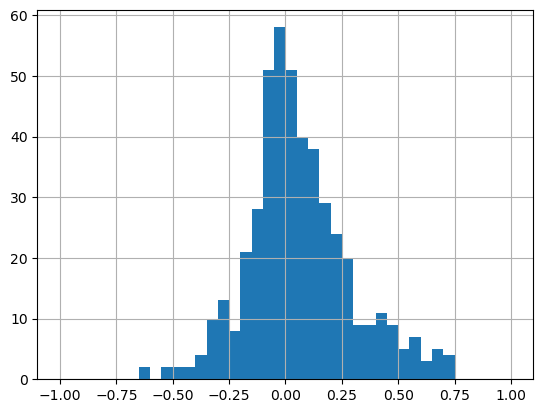

In [36]:
my_bins = np.arange(-1, 1.05, 0.05)
conv_corr_df[conv_corr_df['year']==1]['convergence_correlation'].hist(bins=my_bins)

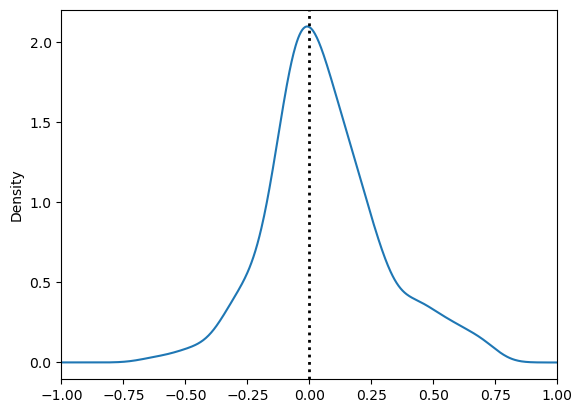

In [37]:
conv_corr_df[conv_corr_df['year']==1]['convergence_correlation'].plot.kde()
plt.axvline(x=0, color='black', linestyle=':', linewidth=2)

plt.xlim(-1, 1)
plt.show()

-0.014808812746247133
-0.003022813184149469
-0.0013708603104479514
0.005544469868660755
-0.01741100619336335
-0.005172647732082705
-0.0022772063366893937
-0.0009382006223507921
0.006820573866020302
-0.013620770479648913
-0.016364445776495665
-0.0031337368731150623
-0.0005180112718979523
0.004724021767539055
-0.015176283012028011
-0.00010257678272808809
-1.0578455389126691e-05
-4.652816751805988e-05
8.145537625822192e-05
-2.5299212651948465e-05
-0.00021261827978306992
-0.00025420578812066825
-0.00010098176486331221
0.0006082997434471425
0.00019778592122658874
-0.002487270345929523
-0.0002698816810785213
-0.00023509861068501928
0.0017985020423546701
-0.0007005016975436516
-0.0008033962522614384
-0.000619215227263271
5.5236799136219815e-05
0.0010329415407547532
-0.001006762748744473
-0.00014061836196980985
-4.871578294587495e-05
-6.998353925951393e-05
0.00021914471734155676
3.620682132914575e-05
-0.0006753304884981442
-5.0060324621393146e-05
-0.00010407954881359677
0.0004459453817783696
-

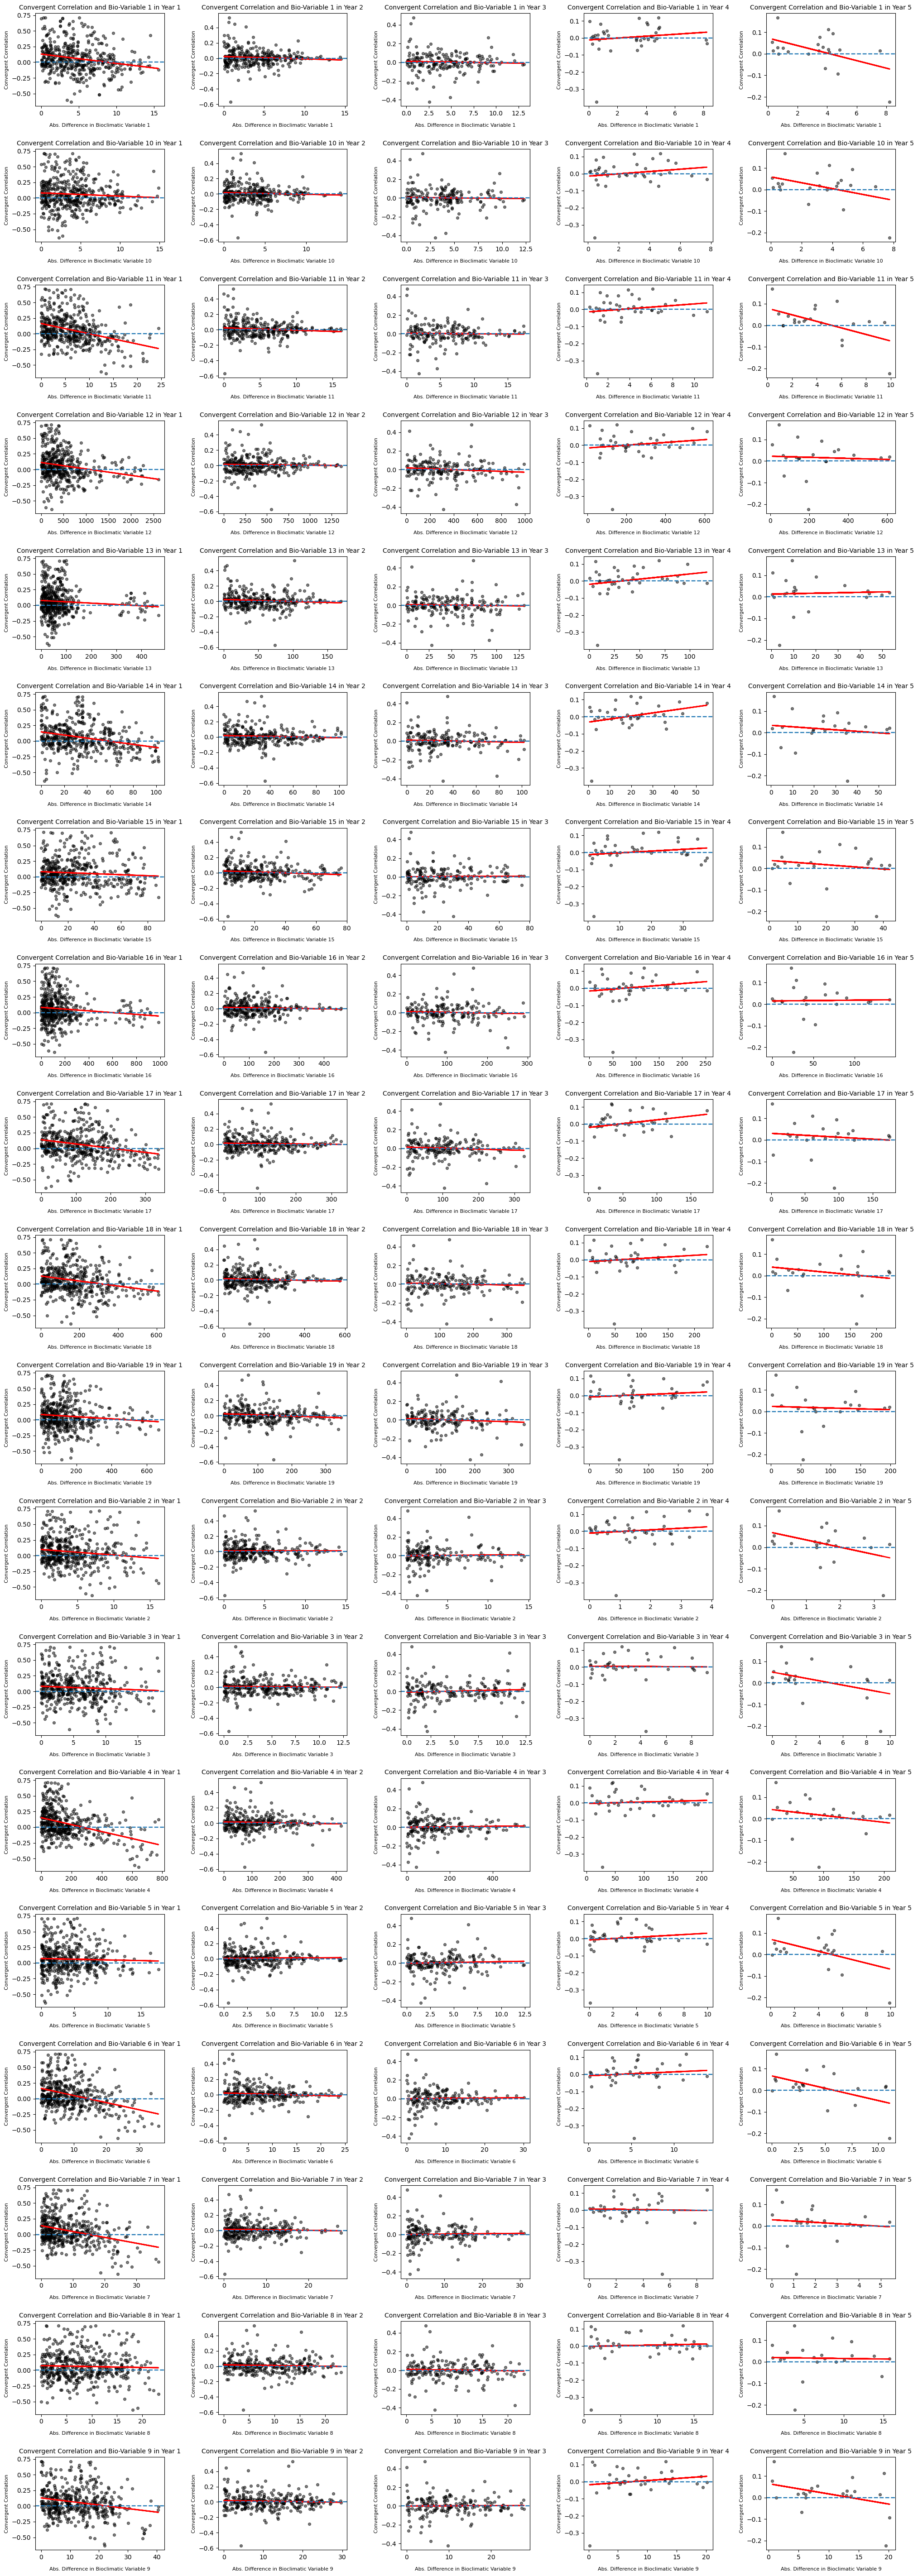

In [40]:
bio_vars_list = sorted(list(set(col for col in bio_table.columns if col != 'site')))
years = ['1', '2', '3', '4', '5']

fig, axes = plt.subplots(nrows=len(bio_vars_list), ncols=len(years), figsize=(20,57))

for row_idx, var in enumerate(bio_vars_list):
    num = var.replace('bio', '')
    bio_diffs = bio_diffs_df[bio_diffs_df['bio variable'] == var].copy()
    
    for col_idx, year in enumerate(years):
        ax = axes[row_idx, col_idx]
        site_comps_year = conv_corr_df[conv_corr_df['year'] == int(year)].copy()
        
        combined_table = pd.merge(site_comps_year, bio_diffs, on='site comparison', how = 'inner')
        combined_table.sort_values(by='bio difference')

        x = combined_table['bio difference']
        y = combined_table['convergence_correlation']
        ax.scatter(x, y, color='black', alpha=0.5, s=18, label='convergent correlation')
        m, b = np.polyfit(x,y, deg=1)
    
        ax.plot(x, m*x+b, color='red', linewidth = 2, label = 'regression line')
        ax.axhline(y=0, ls='--', linewidth=1.7)
        ax.set_title(f"Convergent Correlation and Bio-Variable {num} in Year {year}", fontsize=10, loc='center', color='black')
        ax.set_xlabel(f"Abs. Difference in Bioclimatic Variable {num}", fontsize=8, labelpad=10)
        ax.set_ylabel("Convergent Correlation", fontsize=8)
    
        print(m)

plt.tight_layout(w_pad = 3.0, h_pad=2.0)
plt.savefig(f'convergence_correlation_vs_biovariable_vs_years.pdf', dpi=300, bbox_inches='tight')
plt.show()

0.0001458650734156633


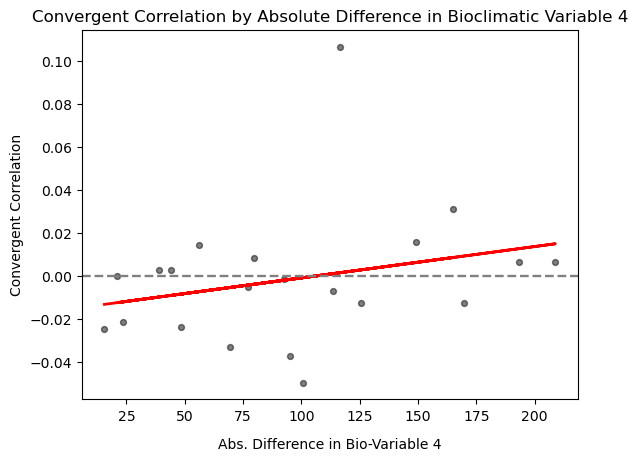

In [36]:
# creates a graph that plots all site comparisons for that year with the corresponding bio-var difference

site_comps_year = conv_corr_df[conv_corr_df['year'] == 5].copy()
bio_diffs_bio1 = bio_diffs_df[bio_diffs_df['bio variable'] == 'bio4'].copy()

combined_table = pd.merge(site_comps_year, bio_diffs_bio1, on='site comparison', how = 'inner')
combined_table.sort_values(by='bio difference')

x = combined_table['bio difference']
y = combined_table['convergence_correlation']
plt.scatter(x, y, color='black', alpha=0.5, s=18, label='convergent correlation')
m, b = np.polyfit(x,y, deg=1)
plt.plot(x, m*x+b, color='red', linewidth = 2, label = 'regression line')
plt.axhline(y=0, ls='--', linewidth=1.7, color='gray')
plt.title("Convergent Correlation by Absolute Difference in Bioclimatic Variable 4", fontsize=12, loc='center', color='black')
plt.xlabel("Abs. Difference in Bio-Variable 4", fontsize=10, labelpad=10)
plt.ylabel("Convergent Correlation", fontsize=10)
#plt.show()
print(m)
plt.savefig(f'convergence_correlation_vs_absbiovariable_transparent.png', dpi=300, bbox_inches='tight')

In [47]:
combined_table.sort_values(by='bio difference').tail(10)

,main_site,other_site,year,convergence_correlation,site comparison,bio variable,site_i,site_j,bio difference
261,23,33,1,0.013688,23-33,bio4,23,33,659.403236
38,2,23,1,-0.047256,2-23,bio4,2,23,661.287876
272,23,55,1,-0.143601,23-55,bio4,23,55,666.838449
273,23,57,1,-0.016355,23-57,bio4,23,57,682.439848
119,6,23,1,-0.168245,6-23,bio4,6,23,697.653553
66,4,23,1,-0.232668,4-23,bio4,4,23,720.815909
264,23,43,1,-0.178082,23-43,bio4,23,43,730.702267
257,23,26,1,0.039084,23-26,bio4,23,26,749.755812
260,23,32,1,-0.239540,23-32,bio4,23,32,764.220739
262,23,37,1,0.108204,23-37,bio4,23,37,774.276905


In [33]:
bio_table.dtypes

site      object
bio1     float64
bio2     float64
bio3     float64
bio4     float64
bio5     float64
bio6     float64
bio7     float64
bio8     float64
bio9     float64
bio10    float64
bio11    float64
bio12    float64
bio13    float64
bio14    float64
bio15    float64
bio16    float64
bio17    float64
bio18    float64
bio19    float64
dtype: object

In [34]:
# bio var differences
# pair differences in bio variables for each site comparison, iterate through the sites to cut out repetitions
# import pathlib
# between_sites_variable_diff = pathlib.Path("between_sites_bio_variables_9-25.csv")

# for var in bio_vars_list:
#     for i, site_i in enumerate(sites[:-1]):
#         for j, site_j in enumerate(sites[i+1:]):
#             ref_val = bio_table.loc[bio_table['site'] == str(site_i), var].values[0]
#             other_site_val = bio_table.loc[bio_table['site'] == str(site_j), var].values[0]
#             difference = abs(other_site_val - ref_val)
            
#             rows = {"bio variable": var, "site_i": str(site_i), "site_j": str(site_j), "bio difference": difference}

#             bio_var_diff_df = pd.DataFrame(rows, index=[0])
#             bio_var_diff_df.to_csv("between_sites_bio_variables_9-25.csv", index=False, mode="a", header = not between_sites_variable_diff.exists())
#     print(f"finished var {var}")
            

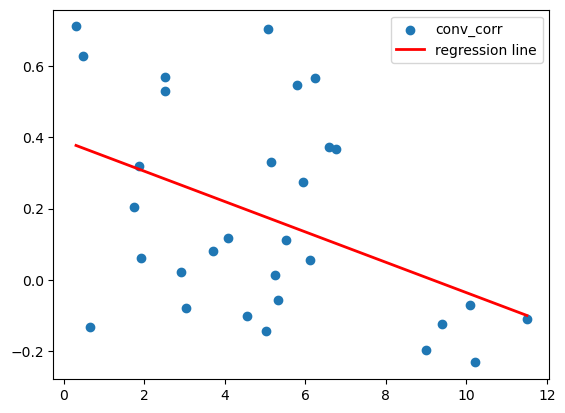

-0.042680237545081684


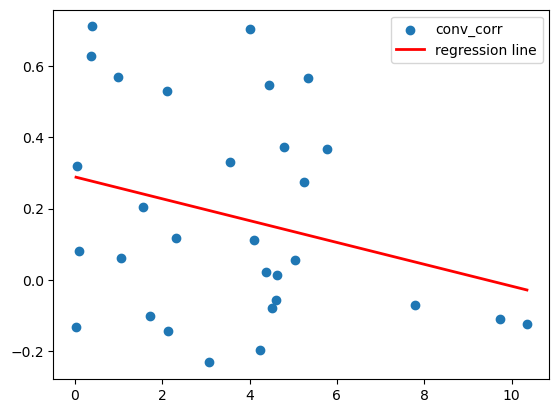

-0.030708855886456943


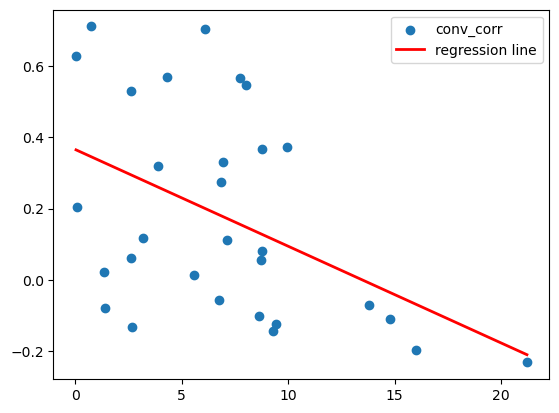

-0.027198586511878106


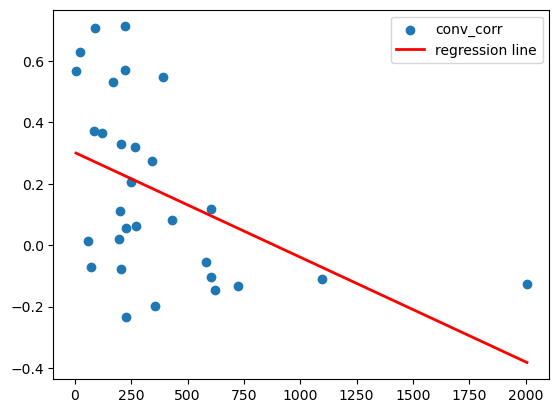

-0.0003408837669922971


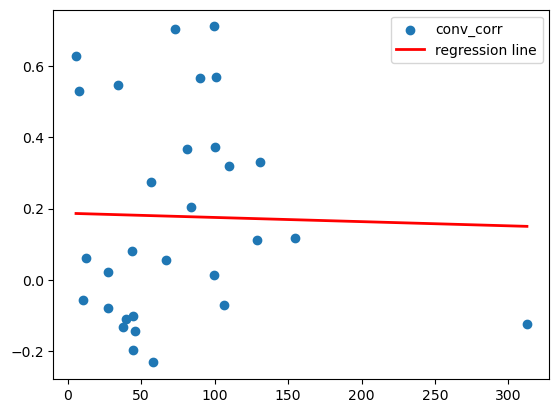

-0.00011781385981907934


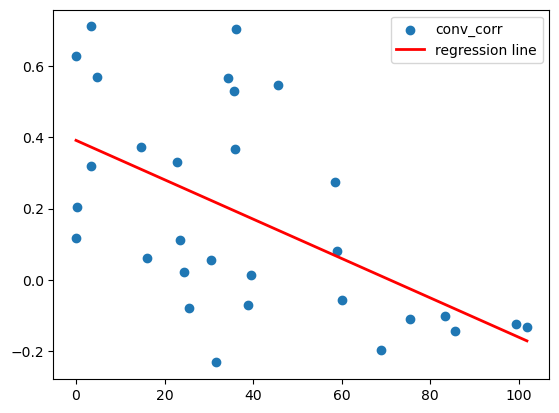

-0.005539064028971449


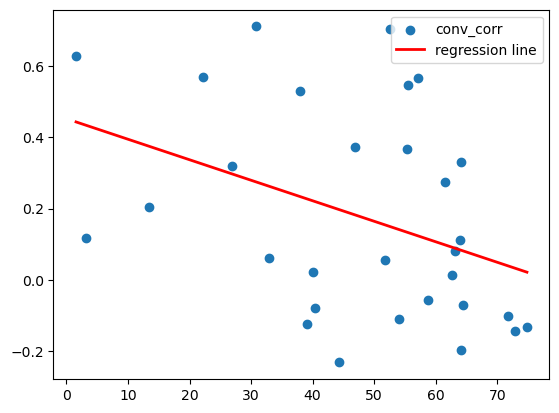

-0.005766725669351472


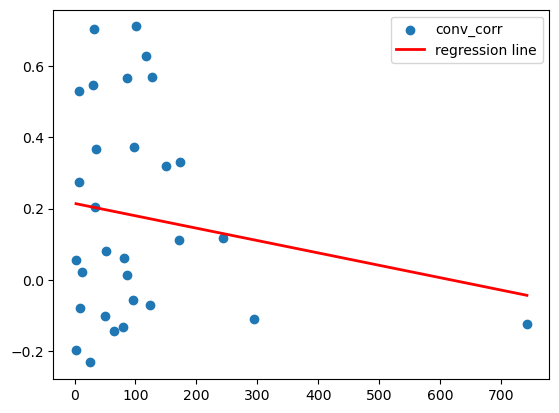

-0.00034810658038618935


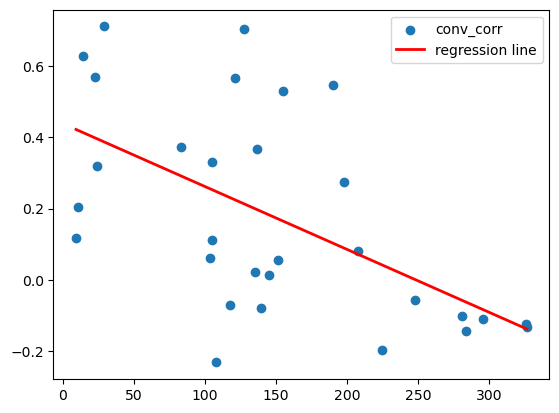

-0.0017677639327828686


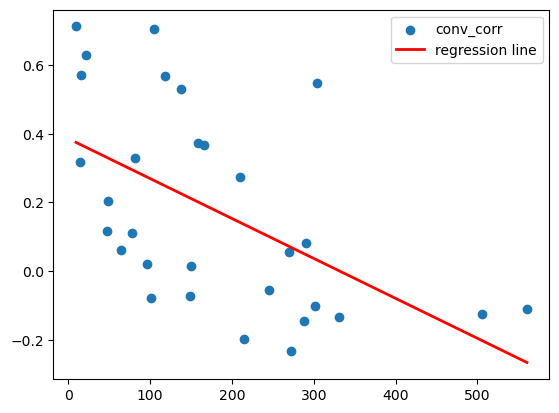

-0.0011627180931606442


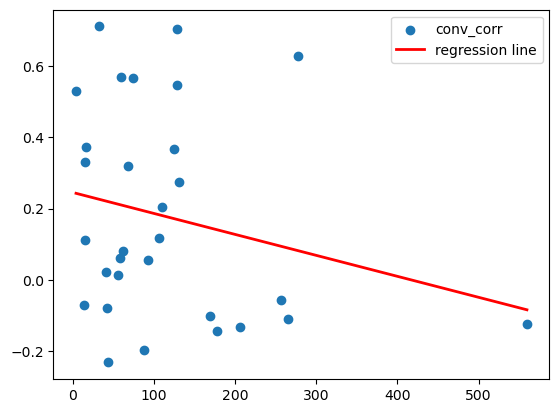

-0.0005898081833379774


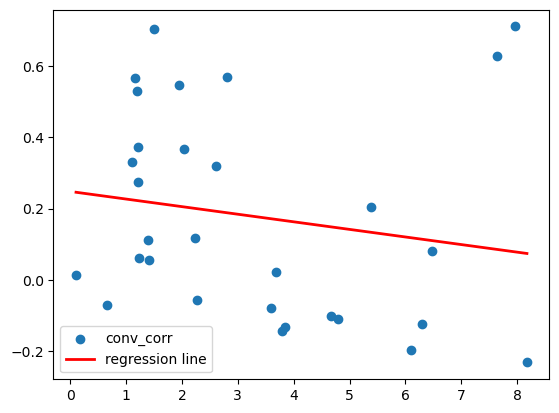

-0.021313514743227926


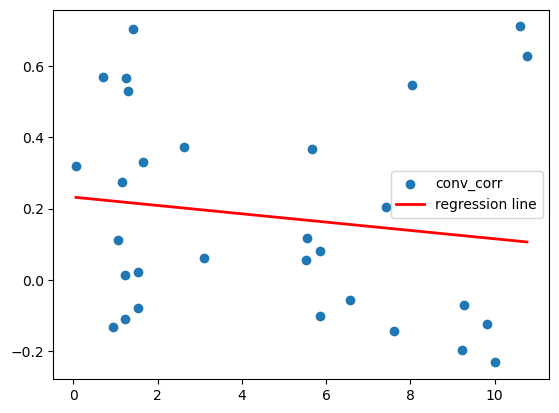

-0.011711823671193717


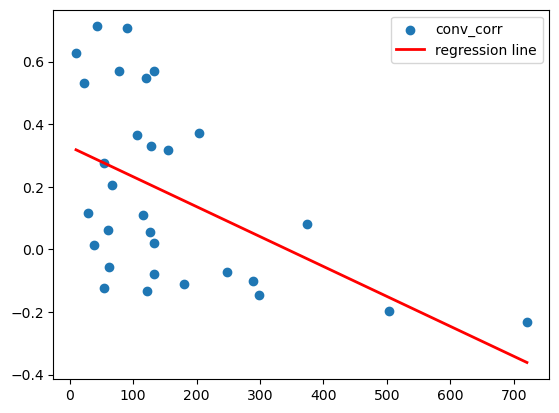

-0.0009557708750833613


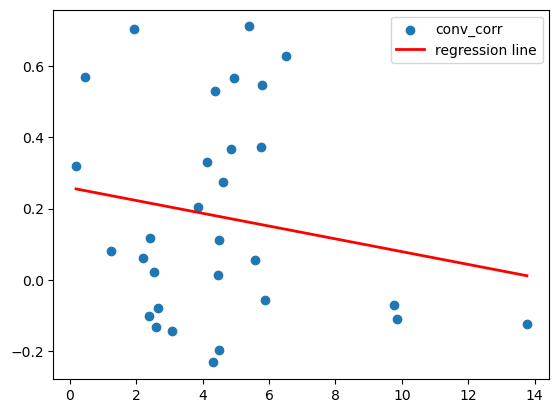

-0.01798614427132785


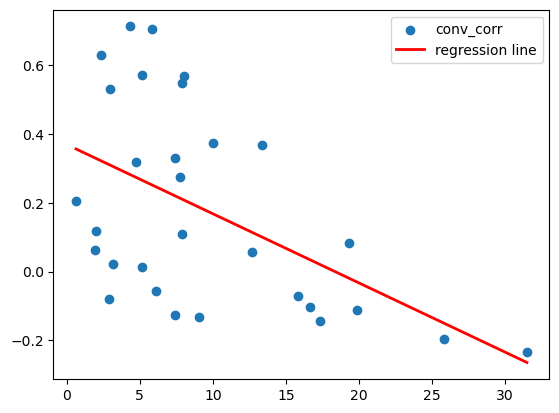

-0.020105945559702378


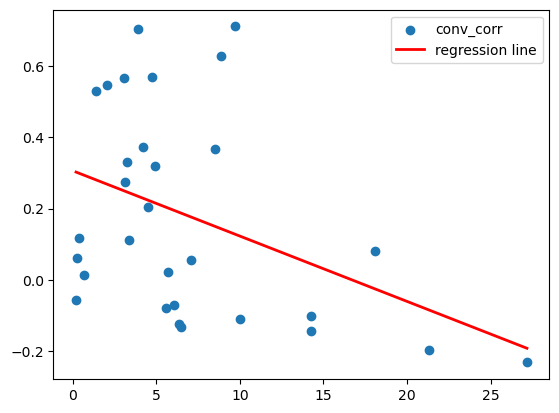

-0.018373622671725133


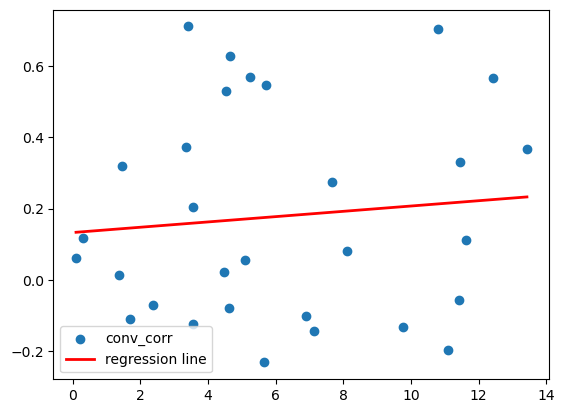

0.0074607050409440994


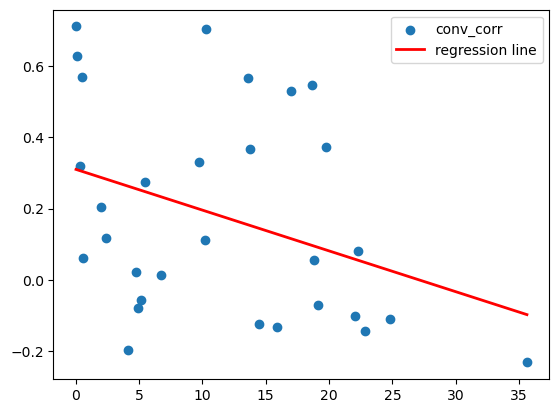

-0.011479846401435182


In [56]:
site_graphs(bio_vars_list, 4, 1)

In [49]:
target_site = 4

pair_diff_vars_w_site1 = pair_diff(bio_table, '4', 'bio1').sort_values(by='diff')
conv_corr_df["main_site"] = conv_corr_df["main_site"].astype(str)
conv_corr_df["other_site"] = conv_corr_df["other_site"].astype(str)
conv_corr_site = conv_corr_df[(conv_corr_df["main_site"] == '4') & (conv_corr_df["year"] == 1) | (conv_corr_df['other_site'] == str(target_site)) & (conv_corr_df["year"] == 1)].copy()
conv_corr_site['site comparison'] = np.where(
    conv_corr_site['main_site'] == str(target_site),
    conv_corr_site['main_site'] + '-' + conv_corr_site['other_site'],
    conv_corr_site['other_site'] + '-' + conv_corr_site['main_site']
)

bio_table_with_corr = pd.merge(pair_diff_vars_w_site1, conv_corr_site, on='site comparison', how = "inner")
bio_table_with_corr

,site comparison,site,diff,main_site,other_site,year,convergence_correlation
0,4-32,32,0.301694,4,32,1,0.712181
1,4-43,43,0.487476,4,43,1,0.629047
2,4-28,28,0.645166,4,28,1,-0.132794
3,4-60,60,1.734577,4,60,1,0.205301
4,4-45,45,1.859188,4,45,1,0.318854
5,4-2,2,1.918848,2,4,1,0.061519
6,4-5,5,2.517119,4,5,1,0.570176
7,4-6,6,2.524395,4,6,1,0.530096
8,4-13,13,2.899236,4,13,1,0.021763
9,4-10,10,3.037449,4,10,1,-0.078318


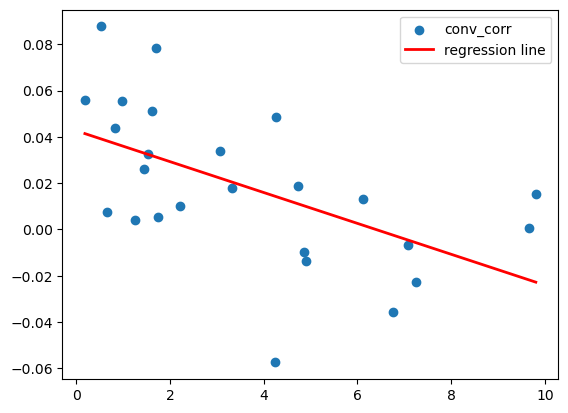

-0.006667797713142956


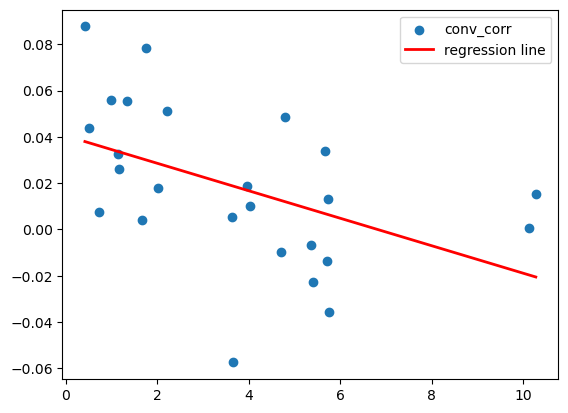

-0.005931600914578673


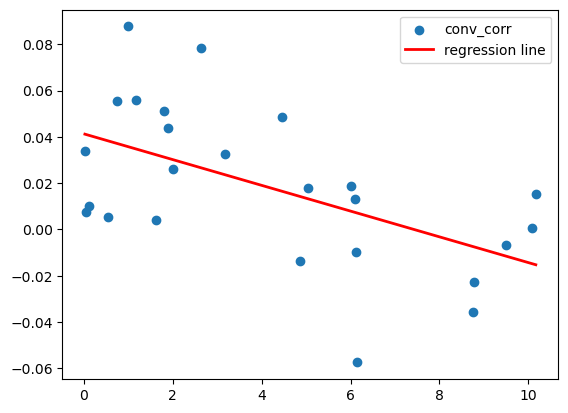

-0.005563951878748748


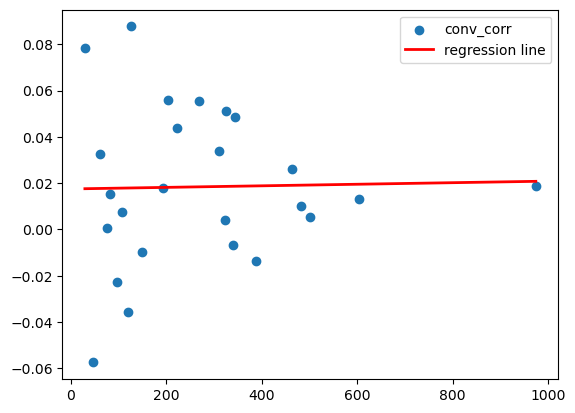

3.3759226887200965e-06


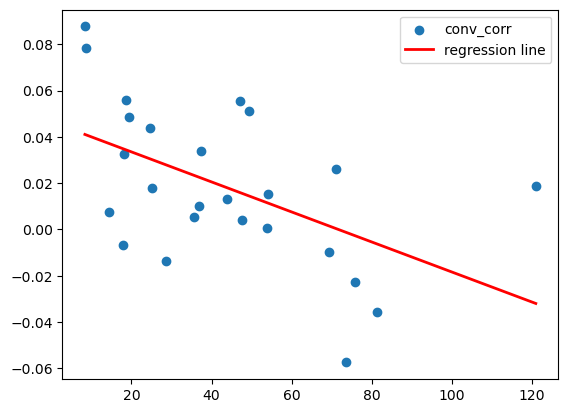

-0.0006487227042709442


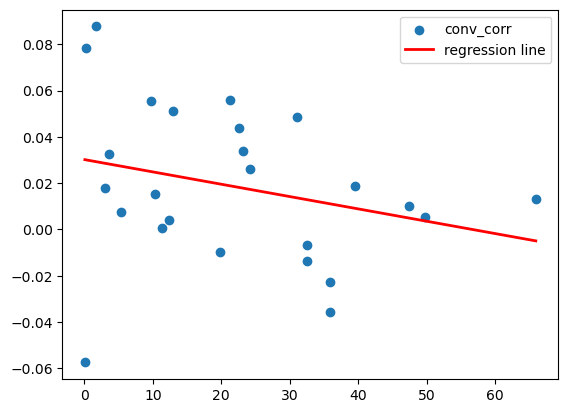

-0.0005325324919801597


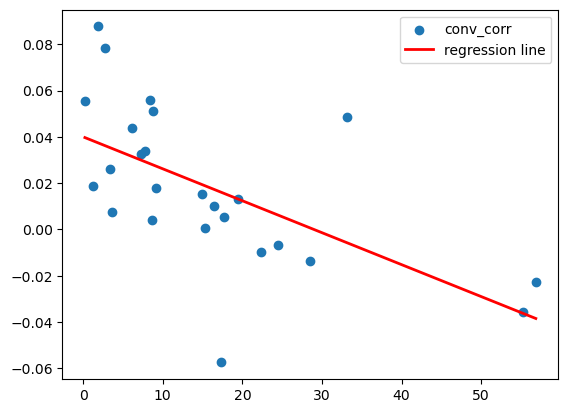

-0.0013790625249548115


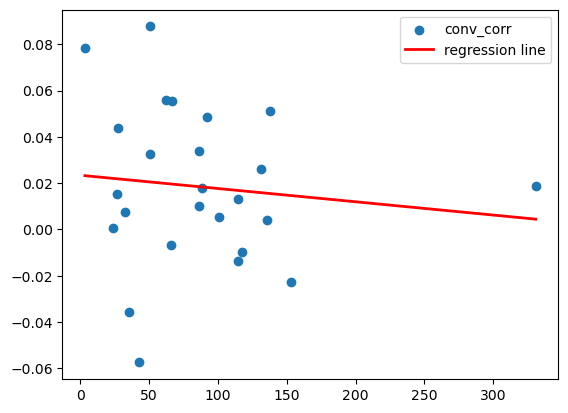

-5.737434880313023e-05


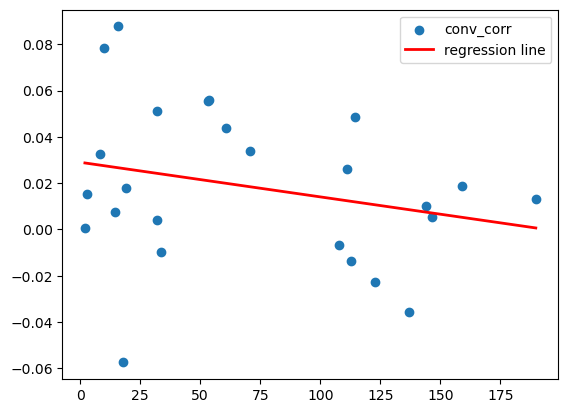

-0.00014949566029874857


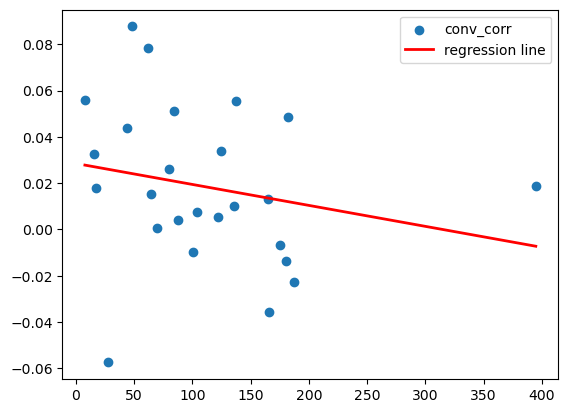

-9.055996515031539e-05


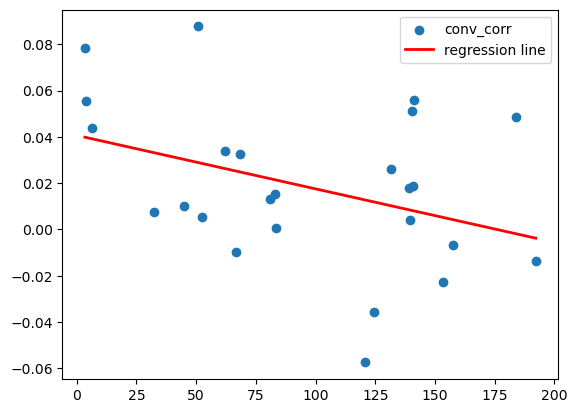

-0.00023109021040275217


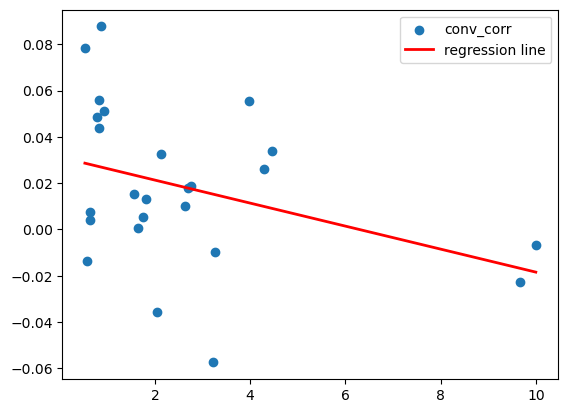

-0.0049683430254614845


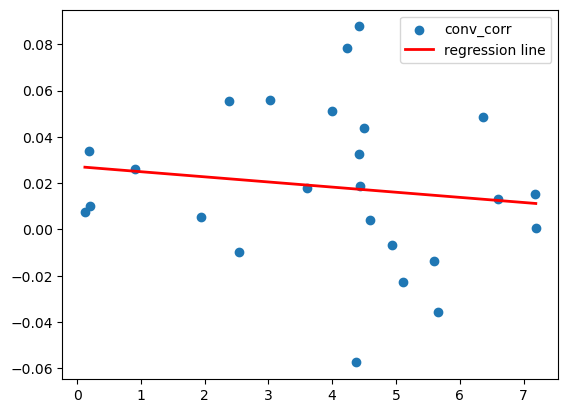

-0.0022163815200456787


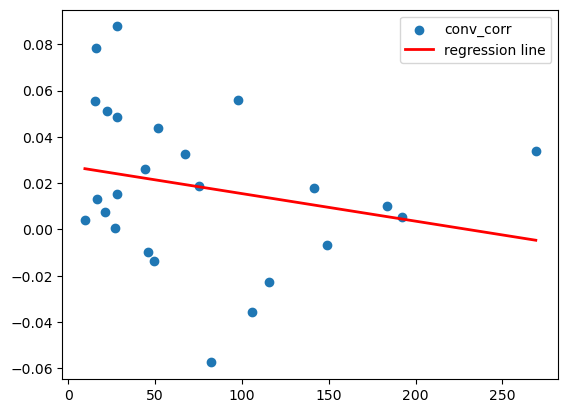

-0.00011895127314639006


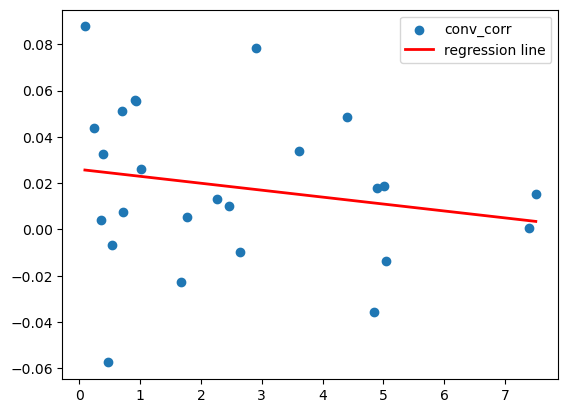

-0.0029924053722097457


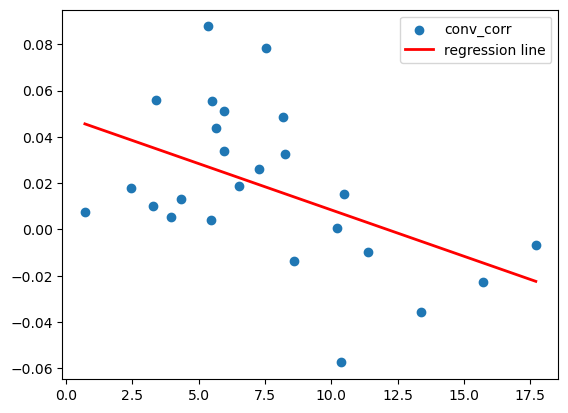

-0.004002942814552737


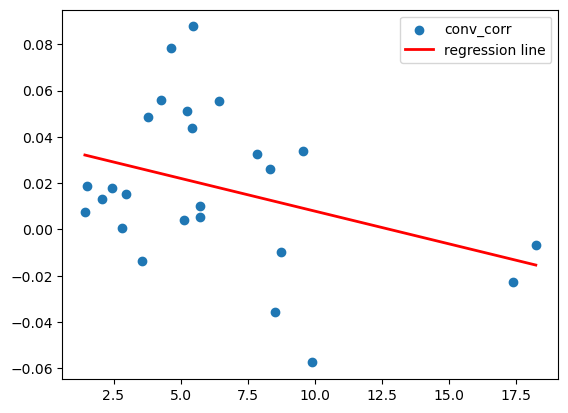

-0.00282554615543058


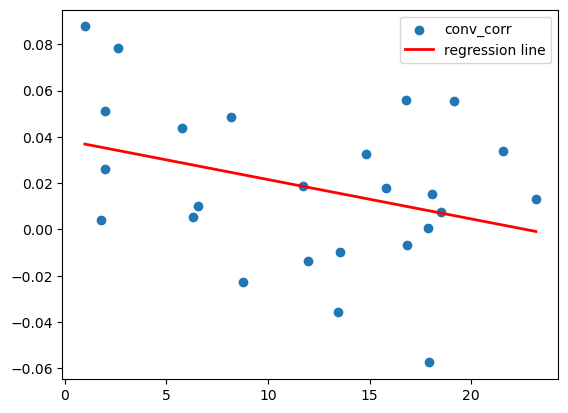

-0.0017010074281472944


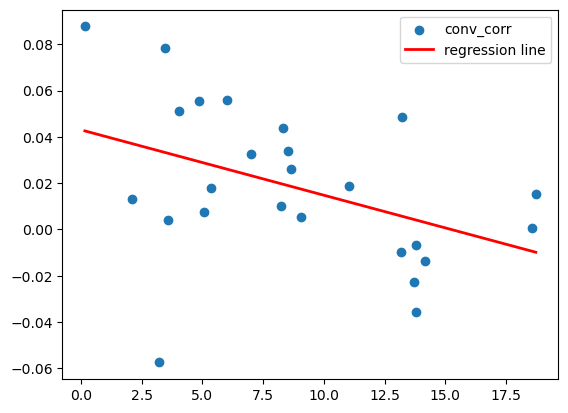

-0.002824413430876606


In [40]:
# bio table with corr using between_sites_conv_corr.csv
# test target site = 1
# table for main_site = 1 and other_site = 1
# future loop, function takes in a year and a main_site

bio_vars_list = sorted(list(set(col for col in bio_table.columns if col != 'site')))
conv_corr_df = pd.read_csv("between_sites_conv_corr_9-22.csv")
%matplotlib inline

conv_corr_df["main_site"] = conv_corr_df["main_site"].astype(str)
conv_corr_df["other_site"] = conv_corr_df["other_site"].astype(str)
values_for_one = conv_corr_df[(conv_corr_df["main_site"] == '1') & (conv_corr_df["year"] == 2)]

for var in bio_vars_list:
    pair_diff_vars_w_site1 = pair_diff(bio_table, '1', var).sort_values(by='diff')
    bio_table_with_corr = pd.merge(pair_diff_vars_w_site1, values_for_one, left_on='site', right_on = "other_site", how = "left")
    bio_table_with_corr.dropna(inplace=True)
    x = bio_table_with_corr['diff']
    y = bio_table_with_corr['convergence_correlation']
    plt.scatter(x,y,label='conv_corr')
    m, b = np.polyfit(x,y, deg=1)
    plt.plot(x, m*x+b, color='red', linewidth = 2, label = 'regression line')
    plt.legend()
    plt.show()
    print(m)

In [ ]:
    concat([pair_diff_vars_w_site1, values_for_one], axis = 1, keys= pair_diff_vars_w_site1["site"])

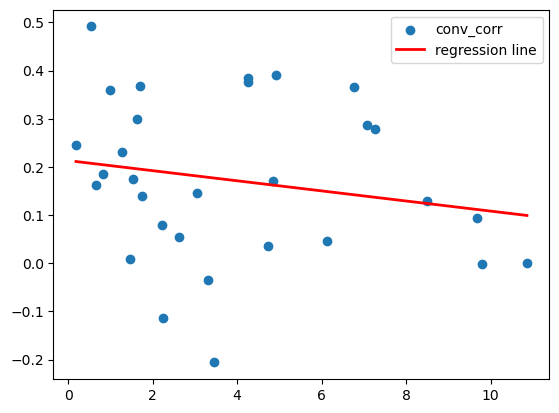

-0.01049130001489836


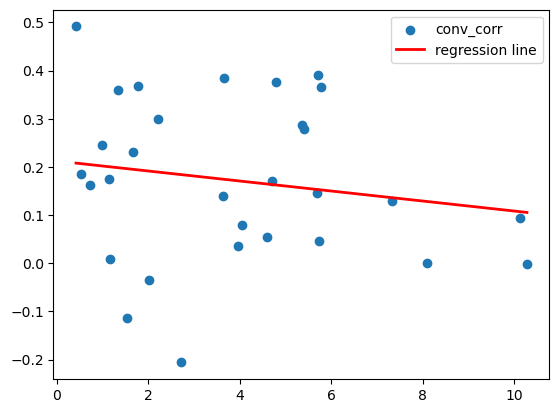

-0.010384151533925341


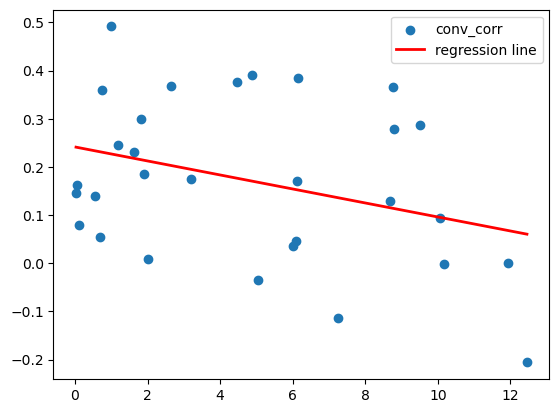

-0.014534390628428335


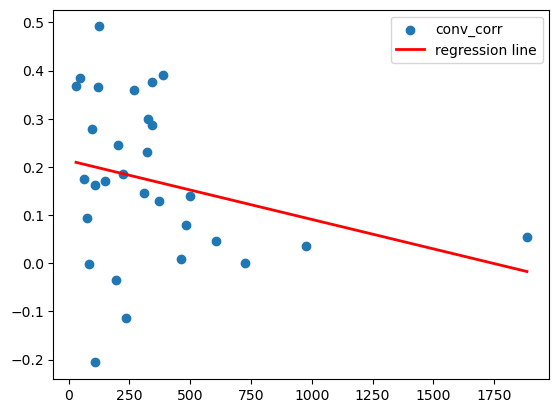

-0.00012221618390637355


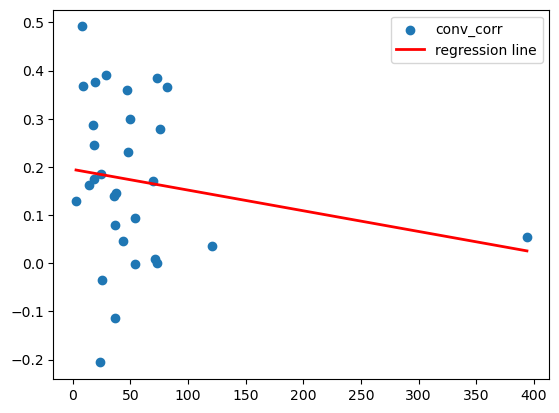

-0.00042958389723032843


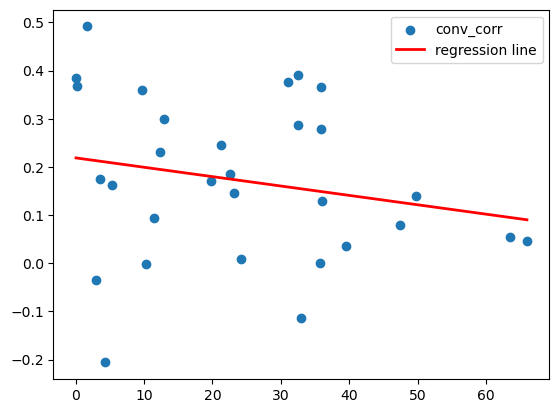

-0.0019492447101792474


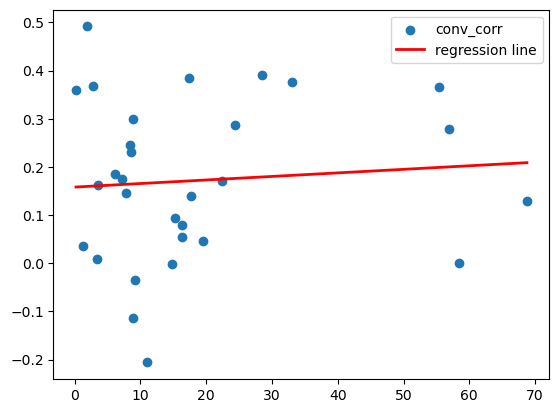

0.0007374835773457867


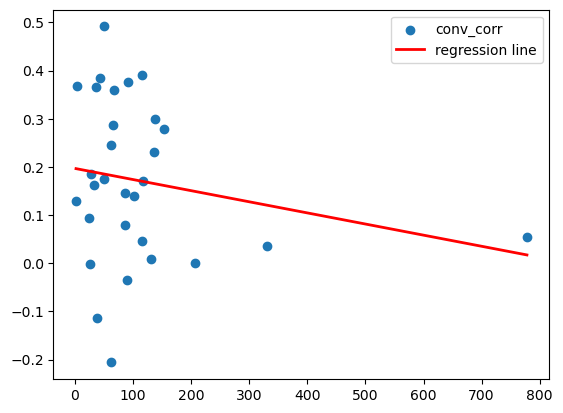

-0.0002308957032954248


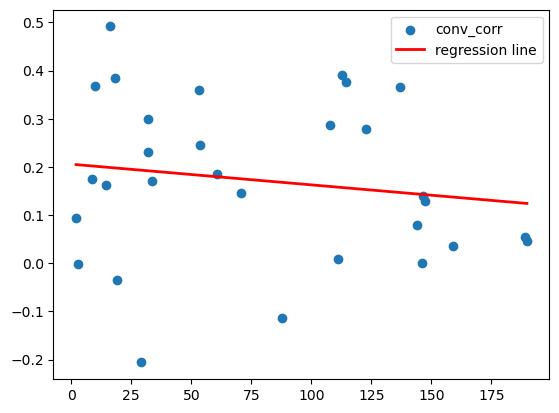

-0.0004296560077089055


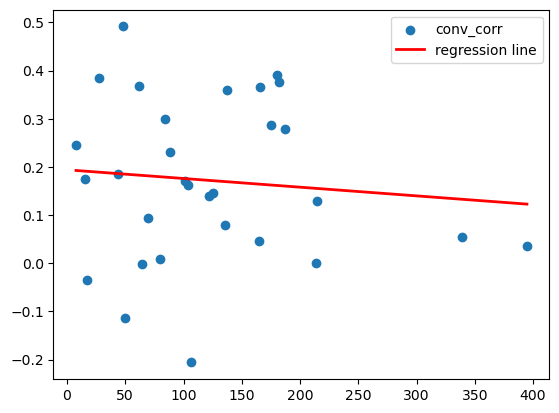

-0.0001804796936146892


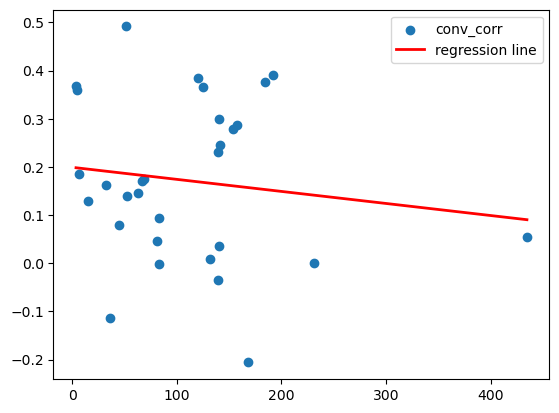

-0.00025006184338689596


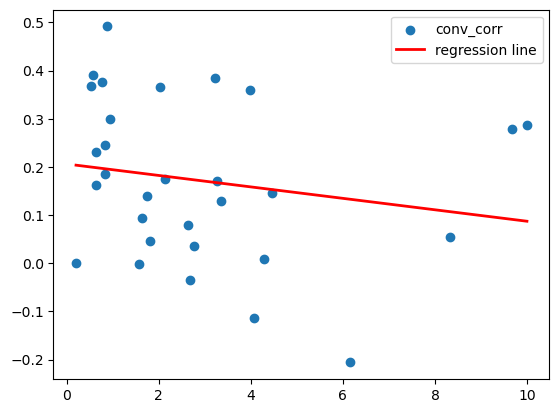

-0.011885014227391077


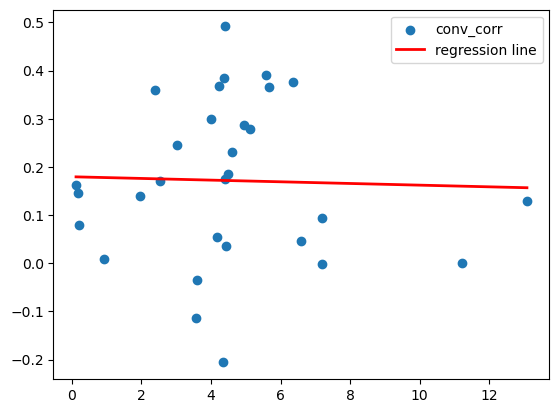

-0.0017419494886906836


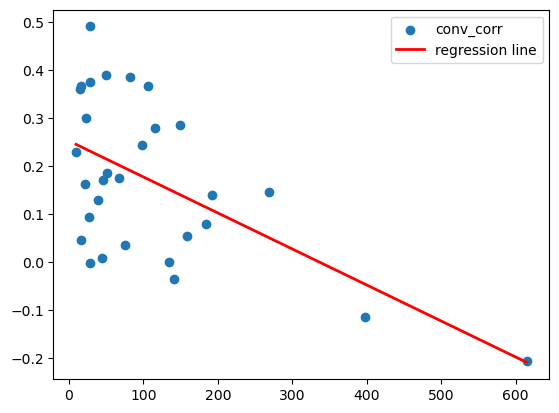

-0.000751680134466674


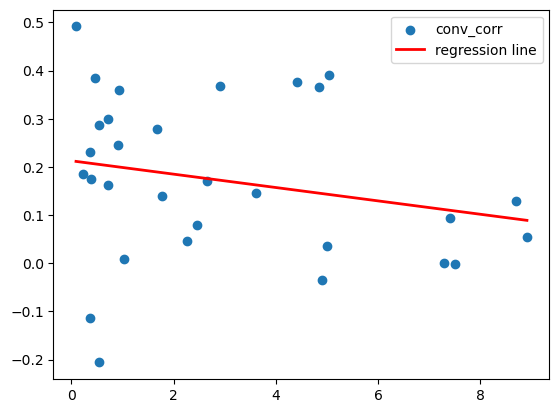

-0.013875519095517251


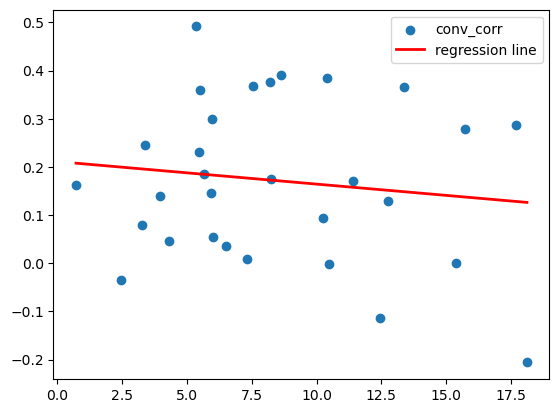

-0.004682228300994452


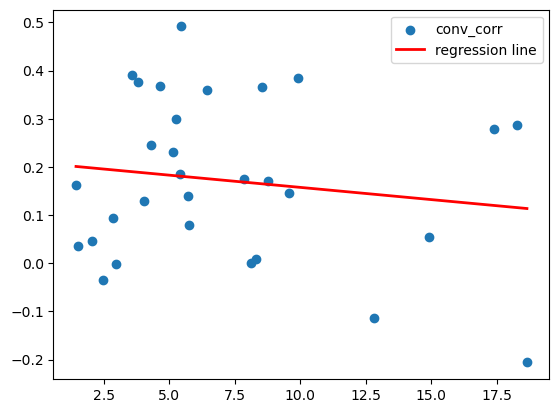

-0.005073298515542622


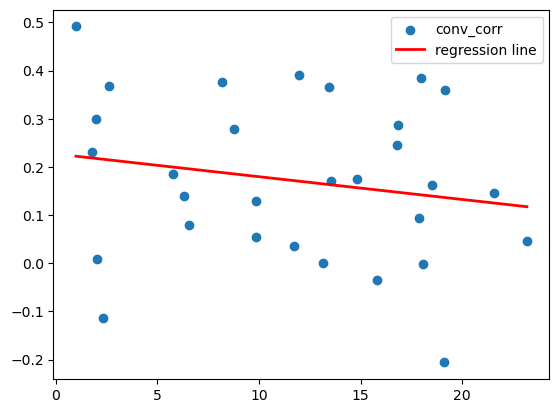

-0.0047274665477490116


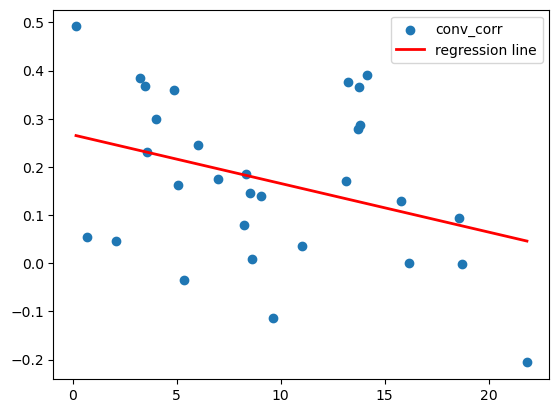

-0.010110287029605196


In [36]:
bio_vars_list = sorted(list(set(col for col in bio_table.columns if col != 'site')))
site_1_comparisons.index = site_1_comparisons.index.astype(str)
%matplotlib inline

for var in bio_vars_list:
    pair_diff_vars_w_site1 = pair_diff(bio_table, '1', var).sort_values(by='diff')
    bio_table_with_corr = pd.merge(pair_diff_vars_w_site1, site_1_comparisons, left_on='site', right_index = True, how = "left")
    bio_table_with_corr.dropna(inplace=True)
    x = bio_table_with_corr['diff']
    y = bio_table_with_corr['convergence_correlation']
    plt.scatter(x,y,label='conv_corr')
    m, b = np.polyfit(x,y, deg=1)
    plt.plot(x, m*x+b, color='red', linewidth = 2, label = 'regression line')
    plt.legend()
    plt.show()
    print(m)

In [29]:
between_sites_values(sites, '57', 1)

1     0.174442
2     0.151679
4     0.013809
5     0.000119
6     0.079632
9     0.239209
10    0.172930
11    0.106457
12    0.102636
13    0.124785
23   -0.016355
24    0.116422
25    0.101079
26    0.025938
27    0.010708
28    0.146827
32   -0.111577
33    0.029878
37    0.175790
42    0.089526
43   -0.047883
45    0.216773
46    0.150028
48   -0.009793
49    0.054705
52    0.078342
53    0.052893
54   -0.002746
55    0.002803
60    0.004619
Name: convergence_correlation, dtype: float64

In [27]:
cov_for_site_57 = delta_p_all_reps_at_site('57').cov()
gens = array_the_gens(cov_for_site_57)
reps = array_the_reps(cov_for_site_57)
convergent_correlation(cov_for_site_57, gens, reps) 

,Gen_1,Gen_2,Gen_3,Gen_4,Gen_5
Gen_1,1.000000,-0.094335,0.069528,-0.048028,0.029680
Gen_2,-0.094335,1.000000,-0.071390,0.024486,0.042071
Gen_3,0.069528,-0.071390,1.000000,-0.048005,-0.064537
Gen_4,-0.048028,0.024486,-0.048005,1.000000,-0.078295
Gen_5,0.029680,0.042071,-0.064537,-0.078295,1.000000


In [26]:
site_27 = delta_p_all_reps_at_site('27')
site_57 = delta_p_all_reps_at_site('57')
gens_27 = array_the_gens(site_27)
gens_57 = array_the_gens(site_57)
reps_27 = array_the_reps(site_27)
reps_57 = array_the_reps(site_57)
between_sites(site_27, site_57, gens_27, gens_57, reps_27, reps_57, '27', '57').loc[1]

0.010707630520566747

In [25]:
site_27 = delta_p_all_reps_at_site('1')
site_57 = delta_p_all_reps_at_site('57')
gens_27 = array_the_gens(site_27)
gens_57 = array_the_gens(site_57)
reps_27 = array_the_reps(site_27)
reps_57 = array_the_reps(site_57)
between_sites(site_27, site_57, gens_27, gens_57, reps_27, reps_57, '1', '57')

1    0.174442
2    0.032565
3    0.034869
4    0.015451
dtype: float64

In [28]:
site_1_comparisons = between_sites_values(sites, '1', 1)

In [33]:
site_1_comparisons.index = site_1_comparisons.index.astype(str)
site_1_bio_table = pair_diff(bio_table, '1', 'bio1').sort_values(by='diff')
bio_table_with_corr = pd.merge(site_1_bio_table, site_1_comparisons, left_on='site', right_index = True, how = "left")
bio_table_with_corr

,site comparison,site,diff,convergence_correlation
18,1-35,35,0.049137,NaN
22,1-42,42,0.183145,0.244781
21,1-41,41,0.239742,NaN
41,1-7,7,0.349039,NaN
25,1-46,46,0.533121,0.491658
10,1-25,25,0.649609,0.162707
7,1-21,21,0.790113,NaN
35,1-55,55,0.820596,0.186290
28,1-49,49,0.977375,0.360412
15,1-30,30,1.058265,NaN


In [41]:
site_1_comparisons.index = site_1_comparisons.index.astype(str)
site_1_bio2_table = pair_diff(bio_table, '1', 'bio2').sort_values(by='diff')
bio2_table_with_corr = pd.merge(site_1_bio2_table, site_1_comparisons, left_on='site', right_index = True, how = "left")
bio2_table_with_corr

,site comparison,site,diff,convergence_correlation
41,1-7,7,0.025296,NaN
21,1-41,41,0.146966,NaN
11,1-26,26,0.202694,0.000017
34,1-54,54,0.527318,0.367692
24,1-45,45,0.579611,0.390549
10,1-25,25,0.629840,0.162707
32,1-52,52,0.634851,0.230280
29,1-5,5,0.775020,0.376070
35,1-55,55,0.824563,0.186290
22,1-42,42,0.828691,0.244781


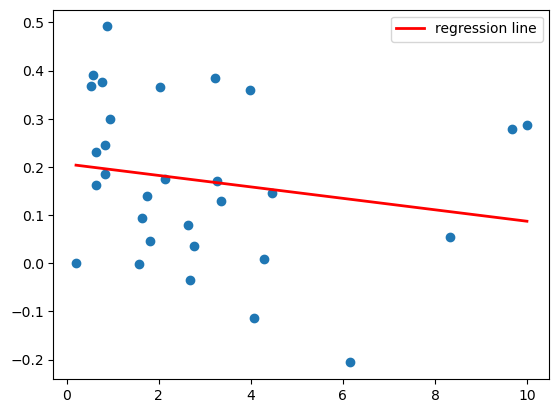

-0.011885014227391077

In [45]:
%matplotlib inline
bio2_table_with_corr.dropna(inplace=True)
s = bio2_table_with_corr['diff']
t = bio2_table_with_corr['convergence_correlation']
#bio_table_with_corr.plot(x = "diff", y = "convergence_correlation", kind = "scatter")
plt.scatter(s,t)
m, b = np.polyfit(s,t, deg=1)
plt.plot(s, m*s+b, color='red', linewidth = 2, label = 'regression line')
plt.legend()
plt.show()
m

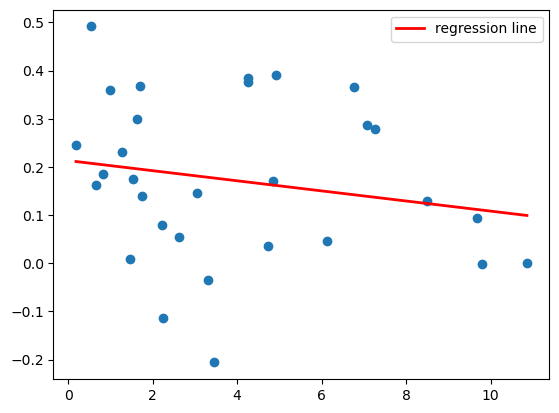

-0.01049130001489836

In [46]:
%matplotlib inline
bio_table_with_corr.dropna(inplace=True)
x = bio_table_with_corr['diff']
y = bio_table_with_corr['convergence_correlation']
#bio_table_with_corr.plot(x = "diff", y = "convergence_correlation", kind = "scatter")
plt.scatter(x,y)
slope, intercept = np.polyfit(x,y, deg=1)
plt.plot(x, slope*x+intercept, color='red', linewidth = 2, label = 'regression line')
plt.legend()
plt.show()
slope

In [ ]:
not_sites = [x for x in site_1_bio_table["site"] if x not in str(sites)]
print(not_sites)

In [43]:
sites

[1,
 2,
 4,
 5,
 6,
 9,
 10,
 11,
 12,
 13,
 23,
 24,
 25,
 26,
 27,
 28,
 32,
 33,
 37,
 42,
 43,
 45,
 46,
 48,
 49,
 52,
 53,
 54,
 55,
 57,
 60]

In [33]:
# bio variables
# idea: be able to grab a column of biovariable differences to become the x-axis for correlation plot
# idea: map out the bio diffs to the sites being compared
# two for loops: iterate from the first position to position n-1, second for loop iterate from i+1 to n
# def pair_diff(X): where X is a column (vector of numbers), 
# two for loops: for i in range(len(x)-1) for j in range(i:len(x)) --> x[i] - x[j]
# abs or square differences
# show which two sites were compared
# goal: have two tables, one is differences in biovariables, other is corr and time
# site 1 compared to all... next: site 2 compared to all...

In [27]:
def plot_it(df, corr_matrix, main_labels, site_name, replicate):
    %matplotlib inline
    
    plt.figure(figsize=(10,6))

    new_list = []
    for s in range(len(main_labels)):
        new_list.append(main_labels[s:])
    print(new_list)

    rows_generation = [
            row.split('_')[1] for row in df.index
        ]
    
    for i in range(len(corr_matrix)-1):
        row_elements = corr_matrix[i,i+1:]
        labels = new_list[i]
        int_labels = [int(x) for x in labels]

        current_gen = rows_generation[i]
        
        plt.plot(int_labels, row_elements, marker='o', label=f'Generation{current_gen}')
        print('x-axis labels =', labels)

    plt.title('Correlation for Site '+ site_name + ', Replicate ' + replicate)
    plt.xlabel('Generation')
    plt.ylabel('Correlation Value')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
    return plt.show()

In [21]:
def find_the_plots_for_the_site_lazy_df(file_path, df_master, site):
    #get the reps from master_df
    site_subset = subset_site_cols_organized(df_master, site)
    reps = array_the_reps(site_subset)
    
    for r in reps:
        subset_df = lazy_load(file_path, df_master, site, str(r))
        subset_df_cov = delta_p_df(subset_df).cov()
        extract_year = [
            col.split('_')[1] for col in subset_df_cov.columns
        ]
        print(extract_year)
        correlation = covariance_to_correlation(subset_df_cov)
        plot_it(correlation, convert_to_matrix(correlation), extract_year[1:], site, str(r))
    return 

In [22]:
def plot_em_together(df, corr_matrix, main_labels, site_name, replicate, ax):
    
    new_list = []
    for s in range(len(main_labels)):
        new_list.append(main_labels[s:])
    print(new_list)

    rows_generation = [
            row.split('_')[1] for row in df.index
        ]
    
    for i in range(len(corr_matrix)-1):
        row_elements = corr_matrix[i,i+1:]
        labels = new_list[i]
        int_labels = [int(x) for x in labels]
        
        current_gen = rows_generation[i]
        
        ax.plot(int_labels, row_elements, marker='o', label=f'Generation{current_gen}')
        print('x-axis labels =', labels)

    ax.set_title(f'Correlation for Site {site_name}, Replicate {replicate}', fontsize=10)
    ax.set_xlabel('Generation', fontsize=8)
    ax.set_ylabel('Correlation', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper left', fontsize=6)

In [23]:
def find_the_plots_save_file_lazy_df(file_path, df_master, site):
    site_subset = subset_site_cols_organized(df_master, site)
    reps = array_the_reps(site_subset)
    
    num_cols = 3
    num_rows = math.ceil(len(reps)/num_cols)
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 4*num_rows))
    axes_flat = axes.flatten() if len(reps)>1 else [axes]
    
    for idx, r in enumerate(reps):
        current_ax = axes_flat[idx]

        subset_df = lazy_load(file_path, df_master, site, str(r))
        subset_df_cov = delta_p_df(subset_df).cov()
        extract_year = [
            col.split('_')[1] for col in subset_df_cov.columns
        ]
        correlation = covariance_to_correlation(subset_df_cov)
        
        plot_em_together(correlation, convert_to_matrix(correlation), extract_year[1:], site, str(r), current_ax)

    for missing_idx in range(len(reps), len(axes_flat)):
        fig.delaxes(axes_flat[missing_idx])

    plt.tight_layout()
    plt.savefig(f'Site_{site}_all_replicates.png', bbox_inches='tight', dpi=150)
    plt.close(fig)


In [51]:
#lazy_load("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, '57', '9').head(10)

In [52]:
#lazy_load("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, '1', '1').head(10)

In [53]:
#for site in sites:
  #  find_the_plots_save_file_lazy_df("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, str(site))

In [54]:
#lazy_load("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, '57', '10').head(10)

In [55]:
#find_the_plots_for_the_site_lazy_df("/global/scratch/users/jennifercasavant/surp2026-covariances/PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, '57')

In [29]:
def find_the_cov_plots_for_the_site(file_path, df_master, site):
    #get the reps from master_df
    site_subset = subset_site_cols_organized(df_master, site)
    reps = array_the_reps(site_subset)
    
    for r in reps:
        subset_df = lazy_load(file_path, df_master, site, str(r))
        subset_df_cov = delta_p_df(subset_df).cov()
        extract_year = [
            col.split('_')[1] for col in subset_df_cov.columns
        ]
        print(extract_year)
        plot_it(subset_df_cov, convert_to_matrix(subset_df_cov), extract_year[1:], site, str(r))
    return 

In [30]:
#find_the_cov_plots_for_the_site("PHASE_1_2_COMBINED_hapFIRE_allele_frequency_random_switch_fixrm.parquet", master_df, '57')